# Guia básico do trabalho: landmarks faciais e detecção de sonolência

Este notebook acompanha o enunciado do trabalho. A ideia é percorrer, com código curto e
muitas figuras, os conceitos que costumam travar quem nunca implementou um sistema desse
tipo: **o que a rede prevê, como os pontos acompanham a imagem, como medir o erro e como
chegar do modelo ao alerta de sonolência**.

> **Isto não é a solução do trabalho.** O modelo treinado aqui é propositalmente simples
> (e ruim). As decisões de projeto — recorte, representação, função de perda, estratégias
> para os olhos, limiares — continuam sendo do grupo e devem ser justificadas no relatório.

**Antes de começar**

*No Google Colab:*

1. No menu, **Ambiente de execução → Alterar o tipo de ambiente de execução → GPU (T4)**.
   Sem GPU o notebook também roda, mas o treino da seção 8 fica menor, mais lento e pior.
2. Rode as células **em ordem** (Shift+Enter). A primeira baixa o dataset (~725 MB) do
   Kaggle para a pasta `data/` e o detector de faces para `modelos/`; as duas aparecem no
   painel de arquivos, à esquerda (ícone de pasta). O download pode levar de 1 a 10
   minutos, conforme a velocidade do Kaggle no momento, então **rode-a logo no início** e
   vá lendo enquanto ela termina. O Colab apaga os arquivos quando a sessão termina, e o
   download se repete a cada sessão.

*No seu computador:*

1. Ative o ambiente do trabalho (`conda activate tpi`) e, no VS Code ou no Jupyter, escolha
   o kernel do ambiente `tpi`.
2. Baixe o dataset com `python src/download_wflw.py`.
3. Abra este notebook **a partir da raiz do projeto** (a pasta que contém `data/` e `src/`).

Cada seção roda em poucos segundos, exceto o treino da seção 8, que leva alguns minutos numa
GPU T4. Sem GPU, ele usa menos dados e chega a um modelo bem pior — os resultados comentados
no texto se referem à execução com GPU.

| Seção | Assunto | No enunciado |
|---|---|---|
| 1 | O problema em uma página | Seções 1 e 2 |
| 2 | O dataset WFLW | 4.1 |
| 3 | Recorte da face | 4.2 |
| 4 | Data augmentation e espelhamento | 5 |
| 5 | Como representar os landmarks | 4.4 e 4.5 |
| 6 | O modelo: backbone e cabeça | 4.3 |
| 7 | Como medir o erro: NME | 6 |
| 8 | Um treino mínimo | 5 e 6 |
| 9 | A medida dos olhos: EAR | 6 e 8 |
| 10 | Da imagem à face: YuNet | 7 |
| 11 | Análise temporal: piscadas e alertas | 9 e 10 |
| 12 | Juntando tudo: `predict.py` e `app.py` | 11 |
| 13 | Checklist de erros silenciosos | — |

## 1. O problema em uma página

Até aqui, vocês provavelmente treinaram redes de **classificação**: a entrada é uma imagem e
a saída é *qual* classe ela contém. Neste trabalho, a rede responde *onde* estão 98 pontos
do rosto (os *landmarks*). A saída são **196 números**: o $x$ e o $y$ de cada ponto, em
pixels.

Essa mudança aparentemente pequena tem consequências em quase todas as etapas:

| | Classificação | Landmarks |
|---|---|---|
| Saída da rede | uma probabilidade por classe | coordenadas $(x, y)$ de cada ponto |
| Recortar / girar / espelhar a imagem | o rótulo não muda | **os pontos precisam ser transformados junto** |
| Depois da previsão | pronto | levar os pontos de volta à imagem original |
| Métrica | acurácia | erro em distância (NME) |

Depois de treinado, o modelo vira **uma peça** de um sistema maior, que roda a cada frame
da webcam:

```
frame ──► detector de faces ──► recorte da face ──► SEU modelo ──► 98 pontos
                                                                      │
alerta ◄── análise no tempo ◄── abertura dos olhos (EAR) ◄────────────┘
```

O ponto mais importante do trabalho está no fim dessa cadeia: **a aplicação depende quase
só dos 16 pontos dos olhos**. Um modelo pode ter um erro médio baixo nos 98 pontos e, ainda
assim, ser inútil para detectar olhos fechados. Vamos ver por quê ao longo do notebook.

Primeiro, a preparação: imports, dataset e detector de faces. No Colab, esta célula baixa
o dataset para `data/`; no seu computador, ela só confere se ele já está lá.

In [1]:
import shutil
import subprocess
import sys
import time
from collections import Counter
from pathlib import Path
from urllib.request import urlretrieve

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch

NO_COLAB = "google.colab" in sys.modules
DATA = Path("data")  # no computador: criada por src/download_wflw.py; no Colab: /content/data

if NO_COLAB and not (DATA / "WFLW_images").exists():
    # O Colab começa vazio: baixamos o WFLW de um espelho público no Kaggle, o mesmo usado
    # por src/download_wflw.py. O kagglehub salva numa pasta escondida (/root/.cache ou
    # /kaggle/input); movemos tudo para data/, que aparece no painel de arquivos.
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    print("Baixando o WFLW (~725 MB); pode levar alguns minutos...")
    # force_download: os arquivos saem do cache do kagglehub quando são movidos para data/
    origem = Path(kagglehub.dataset_download(
        "mrriandmstique/wflw-wider-facial-landmarks-in-the-wild", force_download=True))
    DATA.mkdir(exist_ok=True)
    for pasta in ["WFLW_annotations", "WFLW_images"]:
        if (DATA / pasta).exists():
            continue
        try:
            (origem / pasta).rename(DATA / pasta)  # mesmo disco: só muda de lugar, instantâneo
        except OSError:
            shutil.copytree(origem / pasta, DATA / pasta)  # pasta só de leitura: copia

ANOTACOES = DATA / "WFLW_annotations" / "list_98pt_rect_attr_train_test"
if not ANOTACOES.exists():
    raise FileNotFoundError(
        "Dataset não encontrado. Rode `python src/download_wflw.py` e abra o notebook "
        "a partir da raiz do projeto (a pasta que contém data/ e src/).")

# detector de faces YuNet, usado na seção 10 (~230 KB)
YUNET = Path("modelos/face_detection_yunet_2023mar.onnx")
if not YUNET.exists():
    YUNET.parent.mkdir(exist_ok=True)
    try:
        urlretrieve("https://github.com/opencv/opencv_zoo/raw/main/models/"
                    "face_detection_yunet/face_detection_yunet_2023mar.onnx", YUNET)
    except OSError as erro:
        print("Não foi possível baixar o YuNet; a seção 10 será pulada.", erro)

rng = np.random.default_rng(0)  # semente fixa: os resultados se repetem a cada execução
print("dataset em", DATA)
print("OpenCV", cv2.__version__, "| PyTorch", torch.__version__, "| GPU:",
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "não")
if not torch.cuda.is_available():
    print("Sem GPU, o treino da seção 8 será reduzido. No Colab: Ambiente de execução > "
          "Alterar o tipo de ambiente de execução > GPU.")

dataset em data
OpenCV 4.14.0 | PyTorch 2.5.1+cu121 | GPU: NVIDIA GeForce RTX 4090


## 2. O dataset WFLW

O WFLW tem 10.000 faces anotadas com 98 pontos: 7.500 de treino e 2.500 de teste. As
anotações ficam em arquivos de texto com **uma face por linha**. Antes de escrever qualquer
função, vale olhar uma linha crua:

In [2]:
linhas = (ANOTACOES / "list_98pt_rect_attr_train.txt").read_text().splitlines()
campos = linhas[0].split()

print("número de campos:", len(campos))
print("landmarks (campos 1-196):  ", campos[:4], "...")
print("caixa da face (197-200):   ", campos[196:200])
print("atributos (201-206):       ", campos[200:206])
print("imagem (207):              ", campos[206])

número de campos: 207
landmarks (campos 1-196):   ['309.307007', '538.369019', '317.857345', '560.120847'] ...
caixa da face (197-200):    ['306', '308', '696', '870']
atributos (201-206):        ['0', '0', '1', '0', '0', '0']
imagem (207):               51--Dresses/51_Dresses_wearingdress_51_377.jpg


Os 196 primeiros números são `x0 y0 x1 y1 ... x97 y97`. Um `reshape(98, 2)` coloca cada
landmark em uma linha: `landmarks[k] = (x_k, y_k)`.

> **Cuidado com a numeração.** O enunciado numera os *campos* a partir de 1 (campo 197 = 1º
> valor da caixa), mas o Python indexa a partir de 0: o campo 197 é `campos[196]`. Já os
> *landmarks* são numerados a partir de 0 nos dois lugares (o landmark 60 é `landmarks[60]`).

A função abaixo lê um arquivo inteiro. Cada face vira um dicionário:

In [3]:
ATRIBUTOS = ["pose", "expressão", "iluminação", "maquiagem", "oclusão", "desfoque"]


def ler_anotacoes(split):
    """Lê o arquivo de treino ou de teste: uma FACE (não uma imagem) por linha."""
    faces = []
    for linha in (ANOTACOES / f"list_98pt_rect_attr_{split}.txt").read_text().splitlines():
        campos = linha.split()
        faces.append({
            "landmarks": np.array(campos[:196], dtype=np.float32).reshape(98, 2),
            "caixa": np.array(campos[196:200], dtype=np.float32),  # x_min y_min x_max y_max
            "atributos": np.array(campos[200:206], dtype=int),     # 0 = normal, 1 = difícil
            "imagem": DATA / "WFLW_images" / campos[206],
        })
    return faces


treino = ler_anotacoes("train")
teste = ler_anotacoes("test")

imagens_treino = {f["imagem"] for f in treino}
imagens_teste = {f["imagem"] for f in teste}
print(f"treino: {len(treino)} faces em {len(imagens_treino)} imagens")
print(f"teste:  {len(teste)} faces em {len(imagens_teste)} imagens")
print(f"imagens com faces nos dois conjuntos: {len(imagens_treino & imagens_teste)}")

treino: 7500 faces em 5316 imagens
teste:  2500 faces em 2118 imagens
imagens com faces nos dois conjuntos: 883


### Uma face não é uma imagem

As imagens do WFLW são fotos de eventos (festas, esportes, multidões), e uma mesma imagem
pode ter várias faces anotadas. **O exemplo de treino é a face**, ou seja, a linha do
arquivo. Algumas imagens têm faces no treino e outras faces no teste; a divisão oficial é
por face e deve ser respeitada (não redividam o conjunto).

Uma imagem de grupo do treino, com 16 faces anotadas:

maior número de faces numa mesma imagem do treino: 18


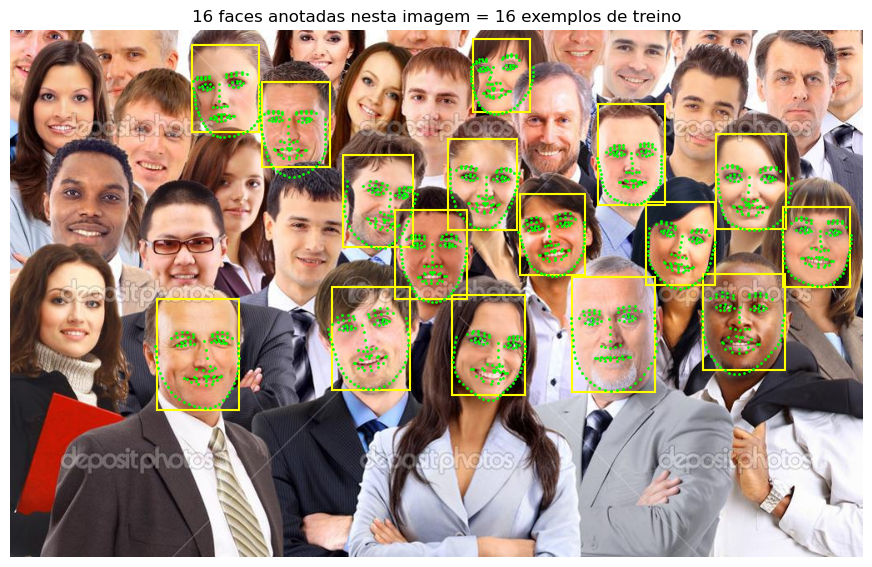

In [4]:
def ler_imagem_rgb(caminho):
    """O OpenCV lê imagens em BGR; convertemos para RGB, que é o que o matplotlib espera."""
    return cv2.cvtColor(cv2.imread(str(caminho)), cv2.COLOR_BGR2RGB)


def desenhar_caixa(ax, caixa, cor, **kwargs):
    x0, y0, x1, y1 = caixa
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=cor, **kwargs))


caminho = DATA / "WFLW_images" / "12--Group" / "12_Group_Large_Group_12_Group_Large_Group_12_27.jpg"
n = sum(f["imagem"] == caminho for f in treino)
print("maior número de faces numa mesma imagem do treino:",
      Counter(f["imagem"] for f in treino).most_common(1)[0][1])

fig, ax = plt.subplots(figsize=(11, 7))
ax.imshow(ler_imagem_rgb(caminho))
for f in treino:
    if f["imagem"] == caminho:
        desenhar_caixa(ax, f["caixa"], "yellow", lw=1.5)
        ax.scatter(*f["landmarks"].T, s=1, c="lime")
ax.set_title(f"{n} faces anotadas nesta imagem = {n} exemplos de treino")
ax.axis("off")
plt.show()

### Os 98 pontos e suas regiões

Cada índice tem um significado fixo. O landmark 60, por exemplo, é sempre o canto externo
do **olho direito da pessoa**, que aparece **à esquerda na imagem** (como numa foto de
alguém de frente para você).

| Região | Índices |
|---|---|
| Contorno facial | 0–32 |
| Sobrancelhas | 33–50 |
| Nariz | 51–59 |
| Olho direito da pessoa (à esquerda na imagem) | 60–67 |
| Olho esquerdo da pessoa (à direita na imagem) | 68–75 |
| Boca | 76–95 |
| Pupilas | 96 e 97 |

Cada olho tem 8 pontos: 2 cantos, 3 na pálpebra superior e 3 na inferior.

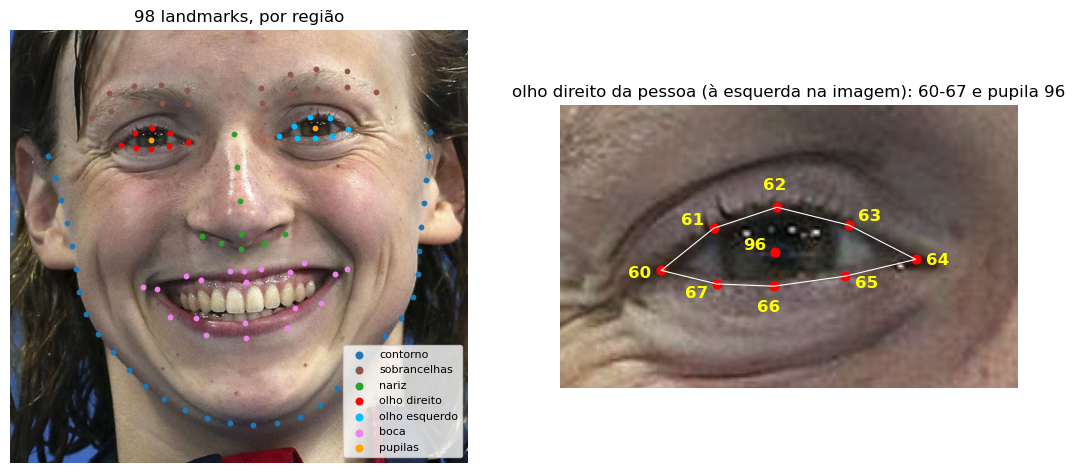

In [5]:
REGIOES = {
    "contorno": range(0, 33), "sobrancelhas": range(33, 51), "nariz": range(51, 60),
    "olho direito": range(60, 68), "olho esquerdo": range(68, 76),
    "boca": range(76, 96), "pupilas": range(96, 98),
}
CORES = {
    "contorno": "tab:blue", "sobrancelhas": "tab:brown", "nariz": "tab:green",
    "olho direito": "red", "olho esquerdo": "deepskyblue", "boca": "violet",
    "pupilas": "orange",
}


def desenhar_landmarks(ax, pts, s=10, legenda=False):
    """Desenha os 98 pontos, com uma cor por região."""
    for nome, indices in REGIOES.items():
        ax.scatter(*pts[list(indices)].T, s=s, c=CORES[nome], label=nome)
    if legenda:
        ax.legend(fontsize=8, loc="lower right", markerscale=1.5)


def aproximar(ax, pts, margem=0.3):
    """Ajusta os eixos para mostrar só a região em volta dos pontos dados."""
    (x0, y0), (x1, y1) = pts.min(0), pts.max(0)
    m = margem * max(x1 - x0, y1 - y0)
    ax.set_xlim(x0 - m, x1 + m)
    ax.set_ylim(y1 + m, y0 - m)  # eixo y invertido: na imagem, y cresce para baixo


def buscar(faces, nome_arquivo):
    """Maior face anotada na imagem com esse nome de arquivo."""
    candidatas = [f for f in faces if f["imagem"].name == nome_arquivo]
    return max(candidatas, key=lambda f: f["caixa"][2] - f["caixa"][0])


frontal = buscar(treino, "41_Swimming_Swimmer_41_701.jpg")  # face grande, de frente
imagem = ler_imagem_rgb(frontal["imagem"])
pts = frontal["landmarks"]

fig, axs = plt.subplots(1, 2, figsize=(13, 6.5))
axs[0].imshow(imagem)
desenhar_landmarks(axs[0], pts, legenda=True)
aproximar(axs[0], pts, margem=0.1)
axs[0].set_title("98 landmarks, por região")

olho = list(range(60, 68)) + [96]
axs[1].imshow(imagem)
axs[1].plot(*pts[list(range(60, 68)) + [60]].T, "-", c="white", lw=0.8)
axs[1].scatter(*pts[olho].T, s=40, c="red")
centro = pts[60:68].mean(0)
for i in olho:
    direcao = pts[i] - centro
    pos = pts[i] + 12 * direcao / (np.linalg.norm(direcao) + 1e-6)
    axs[1].text(*pos, str(i), color="yellow", fontsize=12, ha="center", va="center",
                fontweight="bold")
aproximar(axs[1], pts[60:68], margem=0.4)
axs[1].set_title("olho direito da pessoa (à esquerda na imagem): 60-67 e pupila 96")
for ax in axs:
    ax.axis("off")
plt.show()

Por último, os **atributos**: seis marcações binárias que indicam condições difíceis. Elas
servem para avaliar o modelo por subconjunto (seção 6 do enunciado).

In [6]:
atributos = np.array([f["atributos"] for f in treino])
for nome, fracao in zip(ATRIBUTOS, atributos.mean(0)):
    print(f"{nome:<11s} {100 * fracao:5.1f}% das faces de treino")
print(f"pelo menos uma condição difícil: {100 * atributos.any(1).mean():.1f}%")

pose          3.5% das faces de treino
expressão     2.4% das faces de treino
iluminação   20.4% das faces de treino
maquiagem     1.1% das faces de treino
oclusão      17.9% das faces de treino
desfoque     18.8% das faces de treino
pelo menos uma condição difícil: 48.9%


## 3. Recorte da face

As coordenadas do WFLW estão em pixels da **imagem original**, que tem fundo, corpo e às
vezes dezenas de outras pessoas. A rede, por outro lado, recebe uma entrada de tamanho fixo
(aqui, $256 \times 256$) contendo **apenas a face**. Então, para cada face:

1. tomamos o retângulo anotado (a "caixa");
2. construímos um quadrado com o mesmo centro $\mathbf{c}$ e lado
   $L = 1{,}25 \times$ maior lado da caixa (25% de margem para não cortar o queixo);
3. recortamos esse quadrado e o redimensionamos para $256 \times 256$;
4. aplicamos **a mesma transformação** aos landmarks.

Com escala $s = 256 / L$, um ponto $\mathbf{p}$ da imagem original vai para

$$\mathbf{p}' = s\,(\mathbf{p} - \mathbf{c}) + (128,\ 128).$$

Essa é uma **transformação afim**, e o OpenCV a representa por uma matriz $2 \times 3$
$M$: o ponto vira $M \cdot (x, y, 1)^T$. A vantagem de usar a matriz é que a **mesma** $M$
serve para a imagem (`cv2.warpAffine`) e para os pontos — assim eles nunca se desalinham.

In [7]:
TAMANHO = 256  # resolução de entrada do modelo
MARGEM = 1.25  # lado do recorte = MARGEM x maior lado da caixa


def matriz_recorte(caixa, margem=MARGEM):
    """Matriz afim 2x3 que leva a imagem original ao recorte TAMANHO x TAMANHO.

    Implementa p' = s (p - c) + (TAMANHO/2, TAMANHO/2).
    """
    x0, y0, x1, y1 = caixa
    c = np.array([(x0 + x1) / 2, (y0 + y1) / 2])  # centro da caixa
    lado = margem * max(x1 - x0, y1 - y0)         # lado do quadrado
    s = TAMANHO / lado                            # escala
    t = TAMANHO / 2 - s * c                       # translação
    return np.array([[s, 0, t[0]],
                     [0, s, t[1]]], dtype=np.float32)


def transformar_pontos(pts, M):
    """Aplica a matriz afim 2x3 M a pontos (K, 2) -- a mesma conta que o warpAffine faz."""
    return pts @ M[:, :2].T + M[:, 2]


def recortar(face, M=None):
    """Recorte RGB TAMANHO x TAMANHO da face e seus landmarks no sistema do recorte."""
    if M is None:
        M = matriz_recorte(face["caixa"])
    recorte = cv2.warpAffine(ler_imagem_rgb(face["imagem"]), M, (TAMANHO, TAMANHO))
    return recorte, transformar_pontos(face["landmarks"], M)

Vamos conferir com o exemplo numérico do enunciado (seção 4.2): a face com caixa de
$(692, 90)$ a $(854, 326)$, cujo landmark 60 está em $(720{,}6;\ 190{,}7)$ e deveria ir
para $(82{,}5;\ 113{,}0)$.

In [8]:
exemplo = next(f for f in teste if np.allclose(f["caixa"], [692, 90, 854, 326]))
M = matriz_recorte(exemplo["caixa"])
recorte, pts_recorte = recortar(exemplo, M)

print("matriz M:\n", M.round(3))
print("landmark 60 na imagem original:", exemplo["landmarks"][60].round(1))
print("landmark 60 no recorte:        ", pts_recorte[60].round(1))

matriz M:
 [[   0.868    0.    -542.807]
 [   0.       0.868  -52.502]]
landmark 60 na imagem original: [720.6 190.7]
landmark 60 no recorte:         [ 82.5 113. ]


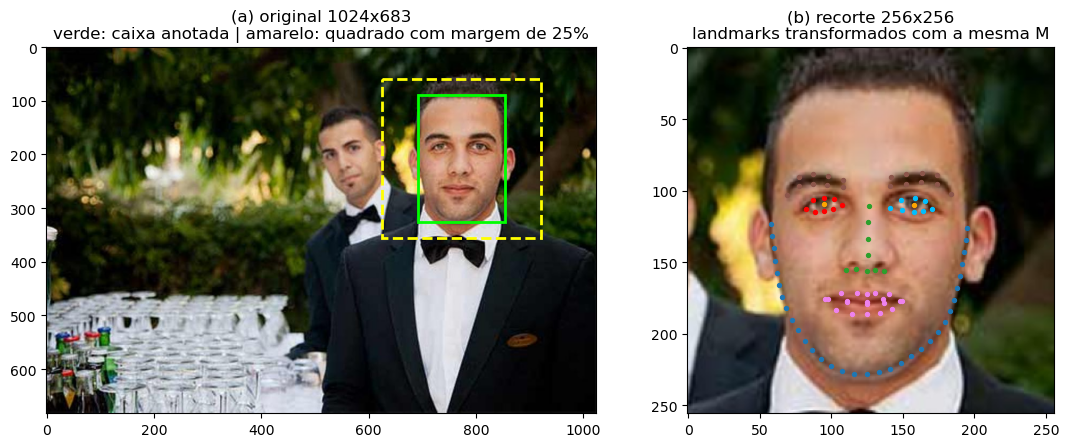

In [9]:
imagem = ler_imagem_rgb(exemplo["imagem"])
x0, y0, x1, y1 = exemplo["caixa"]
c = np.array([(x0 + x1) / 2, (y0 + y1) / 2])
lado = MARGEM * max(x1 - x0, y1 - y0)

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
axs[0].imshow(imagem)
desenhar_caixa(axs[0], exemplo["caixa"], "lime", lw=2)
desenhar_caixa(axs[0], [*(c - lado / 2), *(c + lado / 2)], "yellow", lw=2, ls="--")
axs[0].set_title(f"(a) original {imagem.shape[1]}x{imagem.shape[0]}\n"
                 "verde: caixa anotada | amarelo: quadrado com margem de 25%")
axs[1].imshow(recorte)
desenhar_landmarks(axs[1], pts_recorte, s=8)
axs[1].set_title("(b) recorte 256x256\nlandmarks transformados com a mesma M")
plt.show()

Na **inferência**, o caminho é o inverso: o modelo prevê os pontos no recorte, e a matriz
inversa ($M^{-1}$, dada por `cv2.invertAffineTransform`) os leva de volta para a imagem
original, onde serão desenhados ou avaliados. A ida e a volta devem reproduzir os pontos
originais:

In [10]:
M_inversa = cv2.invertAffineTransform(M)
de_volta = transformar_pontos(pts_recorte, M_inversa)
print(f"erro máximo na ida e volta: {np.abs(de_volta - exemplo['landmarks']).max():.6f} pixels")

erro máximo na ida e volta: 0.000061 pixels


**Por que 25% de margem?** Os landmarks do contorno (queixo, bochechas) ficam perto da borda
da caixa. Com pouca margem, eles saem do recorte e a rede precisaria "adivinhar" pontos
que não vê. Como só precisamos da caixa para isso, dá para medir em todo o treino sem ler
nenhuma imagem:

In [11]:
for margem in [1.0, 1.1, 1.25, 1.4]:
    dentro = []
    for f in treino:
        p = transformar_pontos(f["landmarks"], matriz_recorte(f["caixa"], margem))
        dentro.append(((p >= 0) & (p < TAMANHO)).all())
    print(f"margem {margem:.2f}: todos os 98 pontos dentro do recorte em "
          f"{100 * np.mean(dentro):.1f}% das faces")

margem 1.00: todos os 98 pontos dentro do recorte em 41.4% das faces


margem 1.10: todos os 98 pontos dentro do recorte em 90.9% das faces
margem 1.25: todos os 98 pontos dentro do recorte em 99.2% das faces


margem 1.40: todos os 98 pontos dentro do recorte em 99.9% das faces


> **Atenção.** No vídeo não existe caixa anotada: ela vem de um **detector de faces**
> (seção 10). O recorte precisa seguir **a mesma regra** do treino. Se o modelo for treinado
> com um tipo de recorte e receber outro na webcam (mais justo, mais largo, deslocado), o
> desempenho cai muito — e o problema **não aparece** na avaliação no WFLW.

## 4. Data augmentation e espelhamento

Aumentar os dados (girar, aproximar, deslocar, espelhar) ajuda o modelo a generalizar e a
tolerar recortes imperfeitos do vídeo. Mas, como na seção anterior, **toda transformação
geométrica da imagem precisa ser aplicada também aos pontos**.

A forma mais segura de fazer isso é compor tudo em **uma única matriz afim**. Para compor
duas transformações afins, basta multiplicá-las como matrizes $3 \times 3$ (acrescentando a
linha $[0\ 0\ 1]$). Abaixo, a rotação/escala é feita em torno do centro do recorte, *depois*
da matriz de recorte:

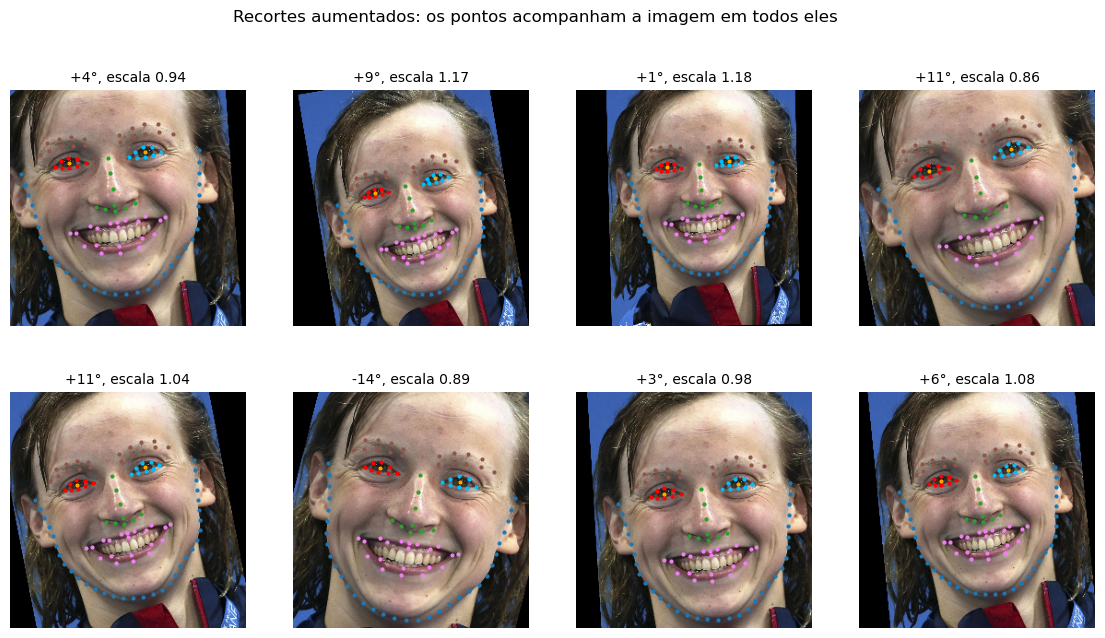

In [12]:
def para_3x3(M):
    return np.vstack([M, [0, 0, 1]])


def matriz_aumentada(caixa, angulo=0.0, escala=1.0, deslocamento=(0.0, 0.0)):
    """Recorte + rotação (graus) + escala + deslocamento (fração do recorte) em uma só matriz.

    escala > 1 aumenta o lado do recorte (afasta a face); escala < 1 aproxima.
    """
    R = cv2.getRotationMatrix2D((TAMANHO / 2, TAMANHO / 2), angulo, 1 / escala)
    R[:, 2] += np.array(deslocamento) * TAMANHO
    return (para_3x3(R) @ para_3x3(matriz_recorte(caixa)))[:2].astype(np.float32)


fig, axs = plt.subplots(2, 4, figsize=(14, 7.2))
for ax in axs.flat:
    params = {"angulo": rng.uniform(-15, 15), "escala": rng.uniform(0.85, 1.2),
              "deslocamento": rng.uniform(-0.06, 0.06, size=2)}
    recorte, pts = recortar(frontal, matriz_aumentada(frontal["caixa"], **params))
    ax.imshow(recorte)
    desenhar_landmarks(ax, pts, s=4)
    ax.set_title(f"{params['angulo']:+.0f}°, escala {params['escala']:.2f}", fontsize=10)
    ax.axis("off")
fig.suptitle("Recortes aumentados: os pontos acompanham a imagem em todos eles", y=0.98)
plt.show()

> **Regra de ouro:** antes de treinar, **desenhe os pontos sobre algumas amostras aumentadas**
> exatamente como elas saem do seu `Dataset`. Quase todo bug de augmentation é visível a
> olho nu e invisível na perda.

### Espelhamento horizontal e o `Mirror98.txt`

O espelhamento é o caso mais traiçoeiro. Ao espelhar a imagem, o olho direito da pessoa
passa a aparecer à **direita** da imagem — ou seja, ele assume o papel de olho
**esquerdo**. Se só a coordenada $x$ for espelhada, o ponto 60 ("canto externo do olho
direito") vai parar no olho que agora é o esquerdo, e o modelo recebe exemplos
contraditórios.

A correção: espelhar $x$ **e depois** trocar cada ponto pelo seu par simétrico, informado
no `Mirror98.txt` (`mirror[i]` = índice do par de $i$):

$$x'_i = W - 1 - x_i, \qquad \mathbf{p}^{\text{novo}}_i = \mathbf{p}'_{\,\text{mirror}[i]}.$$

mirror[0] = 32   (extremidades do contorno)
mirror[60] = 72  (cantos externos dos olhos)
mirror[96] = 97  (pupilas)
mirror[54] = 54  (ponta do nariz: par de si mesma)


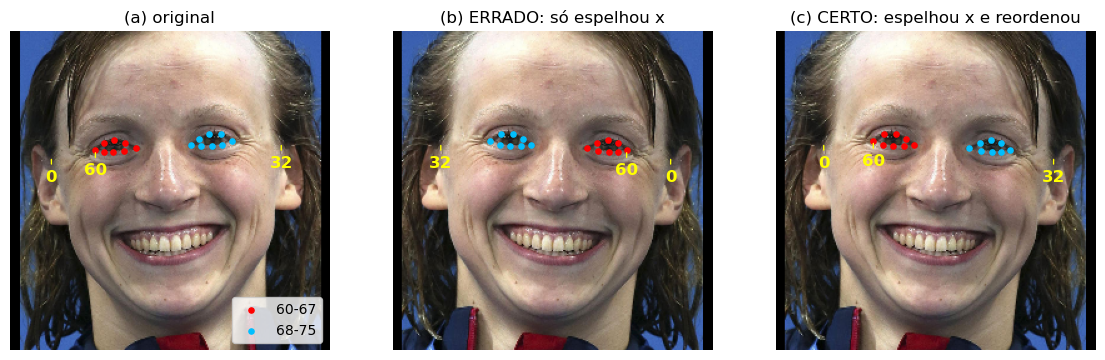

original: olho 60-67 à esquerda na imagem? True
errado  : olho 60-67 à esquerda na imagem? False
certo   : olho 60-67 à esquerda na imagem? True


In [13]:
espelho = np.array((DATA / "WFLW_annotations" / "Mirror98.txt").read_text().strip().split(","),
                   dtype=int)
print("mirror[0] =", espelho[0], "  (extremidades do contorno)")
print("mirror[60] =", espelho[60], " (cantos externos dos olhos)")
print("mirror[96] =", espelho[96], " (pupilas)")
print("mirror[54] =", espelho[54], " (ponta do nariz: par de si mesma)")

recorte, pts = recortar(frontal)
recorte_esp = recorte[:, ::-1]                 # espelha a imagem (inverte as colunas)
pts_esp = pts.copy()
pts_esp[:, 0] = TAMANHO - 1 - pts[:, 0]        # espelha só a coordenada x
pts_certo = pts_esp[espelho]                   # ... e troca cada ponto pelo seu par

fig, axs = plt.subplots(1, 3, figsize=(14, 5))
casos = [(recorte, pts, "(a) original"),
         (recorte_esp, pts_esp, "(b) ERRADO: só espelhou x"),
         (recorte_esp, pts_certo, "(c) CERTO: espelhou x e reordenou")]
for ax, (img, p, titulo) in zip(axs, casos):
    ax.imshow(img)
    ax.scatter(*p[60:68].T, s=14, c="red", label="60-67")
    ax.scatter(*p[68:76].T, s=14, c="deepskyblue", label="68-75")
    for i in [0, 32, 60]:
        ax.annotate(str(i), p[i], xytext=(0, -18), textcoords="offset points", ha="center",
                    color="yellow", fontsize=12, fontweight="bold",
                    arrowprops=dict(arrowstyle="-", color="yellow"))
    ax.set_title(titulo)
    ax.axis("off")
axs[0].legend(loc="lower right")
plt.show()

for nome, p in [("original", pts), ("errado", pts_esp), ("certo", pts_certo)]:
    print(f"{nome:<8s}: olho 60-67 à esquerda na imagem? {p[60, 0] < p[72, 0]}")

> **Atenção.** Esse é um erro **silencioso**: o código roda, a perda cai, mas o modelo fica
> pior — principalmente nos olhos. Um teste automático simples, como o da última linha,
> pode ficar no seu código como `assert`.

## 5. Como representar os landmarks

A rede precisa produzir, de alguma forma, a posição de $K = 98$ pontos. Há duas famílias de
saída (detalhes na seção 4.4 do enunciado):

- **Regressão direta:** a rede produz os $2K = 196$ números diretamente. É simples, mas o
  *pooling* global descarta a informação espacial.
- **Heatmaps (mapas de calor):** a rede produz $K$ imagens pequenas (por exemplo
  $64 \times 64$), uma por ponto, com um "pico" na posição do landmark. A posição é extraída
  do mapa por *argmax* ou por *soft-argmax* (regressão integral).

### Heatmaps

O alvo do landmark $k$ é uma Gaussiana centrada na posição anotada:

$$H_k(x,y) = \exp\left(-\frac{(x-x_k)^2+(y-y_k)^2}{2\sigma^2}\right).$$

Com entrada $256 \times 256$ e mapas $64 \times 64$, cada célula do mapa equivale a
$4 \times 4$ pixels do recorte (**passo** 4). Então $(x_k, y_k)$ e $\sigma$ são medidos em
células: dividimos as coordenadas por 4.

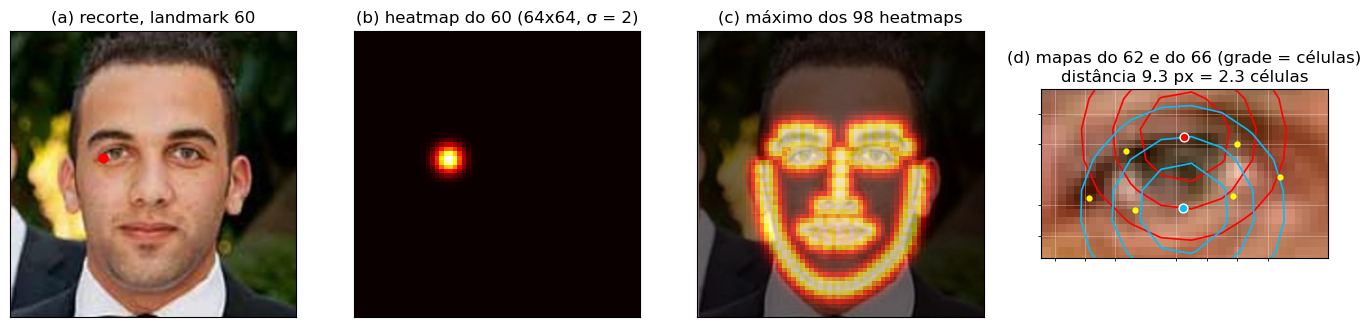

In [14]:
PASSO = 4                       # pixels do recorte por célula do mapa
LADO_MAPA = TAMANHO // PASSO    # 64


def heatmap(ponto, sigma=2.0):
    """Gaussiana LADO_MAPA x LADO_MAPA centrada no ponto (dado em pixels do recorte)."""
    x, y = np.asarray(ponto) / PASSO            # posição em células do mapa
    ys, xs = np.mgrid[0:LADO_MAPA, 0:LADO_MAPA]
    return np.exp(-((xs - x) ** 2 + (ys - y) ** 2) / (2 * sigma ** 2))


recorte, pts = recortar(exemplo)
mapas = np.stack([heatmap(p) for p in pts])  # (98, 64, 64): um mapa por landmark
# extent: posiciona o mapa 64x64 sobre o recorte 256x256 (cada célula cobre 4x4 pixels)
extent = (-PASSO / 2, TAMANHO - PASSO / 2, TAMANHO - PASSO / 2, -PASSO / 2)

fig, axs = plt.subplots(1, 4, figsize=(17, 4.6))
axs[0].imshow(recorte)
axs[0].scatter(*pts[60], s=40, c="red")
axs[0].set_title("(a) recorte, landmark 60")
axs[1].imshow(mapas[60], cmap="hot")
axs[1].set_title("(b) heatmap do 60 (64x64, σ = 2)")
axs[2].imshow(recorte)
axs[2].imshow(mapas.max(0), cmap="hot", alpha=0.6, extent=extent)
axs[2].set_title("(c) máximo dos 98 heatmaps")

axs[3].imshow(recorte)
centros = np.arange(LADO_MAPA) * PASSO  # posição de cada célula do mapa, em pixels do recorte
for i, cor in [(62, "red"), (66, "deepskyblue")]:
    axs[3].contour(centros, centros, mapas[i], levels=[0.25, 0.5, 0.75], colors=cor, linewidths=1.2)
    axs[3].scatter(*pts[i], s=40, c=cor, edgecolors="white", zorder=3)
axs[3].scatter(*pts[[60, 61, 63, 64, 65, 67]].T, s=12, c="yellow", zorder=3)
axs[3].set_xticks(np.arange(-PASSO / 2, TAMANHO, PASSO), minor=True)
axs[3].set_yticks(np.arange(-PASSO / 2, TAMANHO, PASSO), minor=True)
axs[3].grid(which="minor", color="white", lw=0.4, alpha=0.5)
aproximar(axs[3], pts[60:68], margem=0.25)
distancia = np.linalg.norm(pts[62] - pts[66])
axs[3].set_title(f"(d) mapas do 62 e do 66 (grade = células)\n"
                 f"distância {distancia:.1f} px = {distancia / PASSO:.1f} células")
for ax in axs:
    ax.tick_params(labelbottom=False, labelleft=False, length=0)
plt.show()

Repare no painel (d), que mostra as curvas de nível dos mapas dos pontos 62 (pálpebra
superior) e 66 (pálpebra inferior) sobre a grade do mapa: com o olho **aberto**, as
pálpebras estão a só 2 ou 3 células de distância, e as Gaussianas já se sobrepõem. Com o
olho semicerrado, a distância cai para 1 célula ou menos. A região mais importante para a aplicação é justamente a mais difícil para a
resolução dos mapas.

### Decodificação: argmax × soft-argmax

Para tirar a posição de um mapa, o mais simples é pegar o pixel de maior valor (**argmax**)
e multiplicar pelo passo. Só que o argmax devolve posições **inteiras** do mapa, então o
erro de quantização chega a 2 pixels do recorte em cada eixo, mesmo com um mapa perfeito.

O **soft-argmax** transforma o mapa em uma distribuição de probabilidade (softmax sobre
todos os pixels) e devolve o **valor esperado** das coordenadas — uma média ponderada, que
pode cair entre dois pixels:

$$P(x,y) = \frac{e^{\hat{H}(x,y)}}{\sum_{x',y'} e^{\hat{H}(x',y')}},\qquad
\hat{x} = \sum_{x,y} x\,P(x,y),\qquad \hat{y} = \sum_{x,y} y\,P(x,y).$$

Vamos medir os dois em 1.000 posições aleatórias, usando mapas ideais:

In [15]:
def argmax_2d(mapa):
    y, x = np.unravel_index(mapa.argmax(), mapa.shape)
    return np.array([x, y]) * PASSO


def argmax_refinado(mapa, raio=3):
    """Argmax + média ponderada pelos próprios valores do mapa numa janela 7x7 (sem softmax)."""
    y, x = np.unravel_index(mapa.argmax(), mapa.shape)
    y0, y1 = max(y - raio, 0), min(y + raio + 1, mapa.shape[0])
    x0, x1 = max(x - raio, 0), min(x + raio + 1, mapa.shape[1])
    janela = mapa[y0:y1, x0:x1]
    ys, xs = np.mgrid[y0:y1, x0:x1]
    return np.array([(xs * janela).sum(), (ys * janela).sum()]) / janela.sum() * PASSO


def soft_argmax_2d(logits):
    p = np.exp(logits - logits.max())
    p /= p.sum()                                     # softmax espacial: soma 1
    ys, xs = np.mgrid[0:LADO_MAPA, 0:LADO_MAPA]
    return np.array([(xs * p).sum(), (ys * p).sum()]) * PASSO  # valor esperado


posicoes = rng.uniform(40, 216, size=(1000, 2))  # posições reais, em pixels do recorte
decodificadores = {
    "argmax": argmax_2d,
    "argmax + refinamento local (7x7)": argmax_refinado,
    "soft-argmax, saída com pico forte (20·H)": lambda H: soft_argmax_2d(20 * H),
    "soft-argmax direto no heatmap 0-1 (H)": soft_argmax_2d,
}
erros = {nome: [] for nome in decodificadores}
for p in posicoes:
    H = heatmap(p)
    for nome, decodificar in decodificadores.items():
        erros[nome].append(np.linalg.norm(decodificar(H) - p))

for nome, e in erros.items():
    print(f"{nome:<42s} erro médio {np.mean(e):6.2f} px | máximo {np.max(e):6.2f} px")

argmax                                     erro médio   1.51 px | máximo   2.80 px
argmax + refinamento local (7x7)           erro médio   0.50 px | máximo   0.92 px
soft-argmax, saída com pico forte (20·H)   erro médio   0.17 px | máximo   0.25 px
soft-argmax direto no heatmap 0-1 (H)      erro médio  67.38 px | máximo 120.59 px


Quatro lições:

1. O **argmax** tem erro médio de ~1,5 px e máximo de quase 3 px, só por quantização.
2. O **refinamento local** — depois do argmax, uma média ponderada das posições numa janela
   pequena em volta do pico, usando os próprios valores do mapa — corrige boa parte desse
   erro, sem softmax.
3. O **soft-argmax** chega a uma fração de pixel quando a saída da rede tem um pico forte.
   Ele também é **diferenciável**, então dá para treinar a rede com uma perda diretamente nas
   coordenadas.
4. **Armadilha:** o soft-argmax aplicado **direto** num heatmap com valores entre 0 e 1 erra
   por dezenas de pixels. Vale entender por quê.

#### Por que o softmax direto no heatmap dá errado?

O soft-argmax é uma **média ponderada** das posições do mapa. O peso de cada pixel é
$e^{\text{valor do pixel}}$ (é isso que o softmax faz), e a posição prevista é a média das
posições com esses pesos.

Num heatmap Gaussiano, os valores vão de 0 a 1:

- o pixel do pico vale 1, e seu peso é $e^1 \approx 2{,}7$;
- um pixel longe do ponto vale 0, e seu peso é $e^0 = 1$.

Ou seja, o pico pesa só **2,7 vezes** mais que um pixel vazio. Só que os pixels vazios são
quase todos: o mapa tem 4.096 pixels, e só uns 100 ficam perto do ponto. Somando tudo, quase
toda a probabilidade fica espalhada pelo mapa, e a média ponderada de pontos espalhados por
igual é... o **centro do mapa**. A figura mostra isso para um ponto real na célula (10, 10):

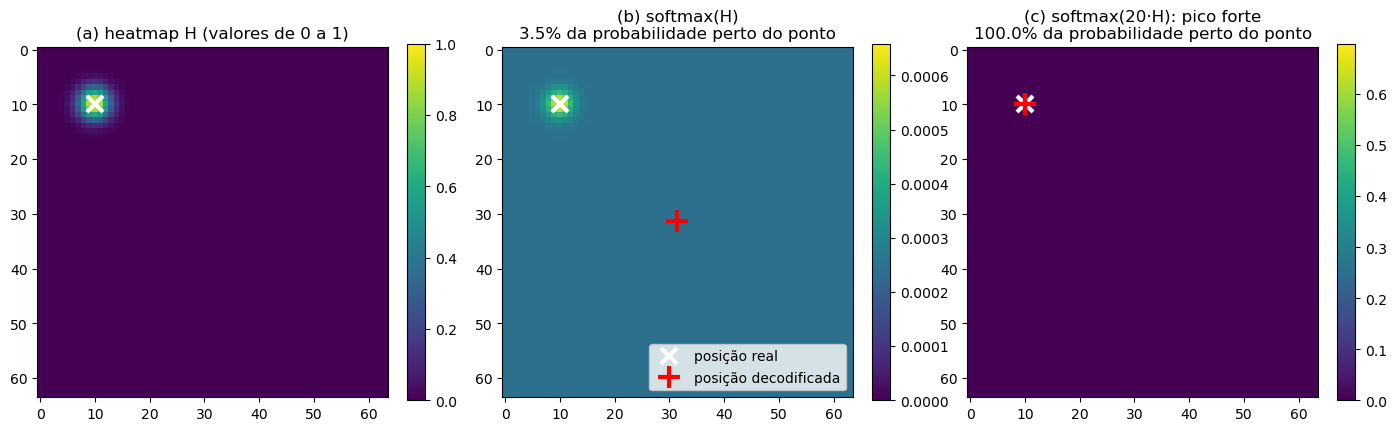

pixels no mapa: 4096 | pixels a até 6 células do ponto: 113
peso do pico / peso de um pixel vazio: 2.7 no softmax(H), 4.9e+08 no softmax(20·H)
softmax(H)     posição decodificada: [125.3 125.3] px (real: [40. 40.] px; centro do recorte: [128. 128.])
softmax(20·H)  posição decodificada: [40. 40.] px (real: [40. 40.] px; centro do recorte: [128. 128.])


In [16]:
ponto = np.array([40.0, 40.0])  # posição real, em pixels do recorte = célula (10, 10) do mapa
H = heatmap(ponto)
ys, xs = np.mgrid[0:LADO_MAPA, 0:LADO_MAPA]
perto = np.hypot(xs - ponto[0] / PASSO, ys - ponto[1] / PASSO) <= 6  # até 6 células do ponto


def softmax_2d(logits):
    p = np.exp(logits - logits.max())
    return p / p.sum()


paineis = [(H, "(a) heatmap H (valores de 0 a 1)", None),
           (softmax_2d(H), "(b) softmax(H)", soft_argmax_2d(H)),
           (softmax_2d(20 * H), "(c) softmax(20·H): pico forte", soft_argmax_2d(20 * H))]
fig, axs = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, (mapa, titulo, previsto) in zip(axs, paineis):
    im = ax.imshow(mapa, cmap="viridis", vmin=0)  # vmin=0: o "fundo" aparece se não for zero
    fig.colorbar(im, ax=ax, fraction=0.046)
    ax.plot(*(ponto / PASSO), "x", c="white", ms=12, mew=3, label="posição real")
    if previsto is not None:
        ax.plot(*(previsto / PASSO), "+", c="red", ms=16, mew=3, label="posição decodificada")
        titulo += f"\n{100 * mapa[perto].sum():.1f}% da probabilidade perto do ponto"
    ax.set_title(titulo)
axs[1].legend(loc="lower right")
plt.show()

print(f"pixels no mapa: {LADO_MAPA ** 2} | pixels a até 6 células do ponto: {perto.sum()}")
print(f"peso do pico / peso de um pixel vazio: {np.exp(1):.1f} no softmax(H), "
      f"{np.exp(20):.2g} no softmax(20·H)")
for nome, mapa in [("softmax(H)", H), ("softmax(20·H)", 20 * H)]:
    print(f"{nome:<14s} posição decodificada: {soft_argmax_2d(mapa).round(1)} px "
          f"(real: {ponto} px; centro do recorte: [128. 128.])")

No painel (b), o mapa inteiro fica "aceso": cada pixel vazio ainda tem cerca de um terço do
peso do pico ($1/2{,}7$). Por isso, só uma pequena fração da probabilidade fica perto do
ponto, e a posição decodificada (cruz vermelha) vai parar perto do centro do mapa, longe
da posição real. No painel (c), multiplicar o mapa por 20 faz o pico pesar $e^{20}$ — cerca
de 500 milhões de vezes — mais que um pixel vazio: toda a probabilidade fica no ponto, e a
decodificação acerta.

**Regra prática: a decodificação tem que combinar com o jeito como a rede foi treinada.**

- **Treino com MSE contra alvos Gaussianos:** a rede aprende a imitar o alvo e produz mapas
  com valores entre 0 e 1. Decodifique com **argmax + refinamento local**
  (`argmax_refinado`), sem softmax.
- **Treino com soft-argmax e perda nas coordenadas:** a saída da rede não é um heatmap de 0
  a 1, e sim "pontuações" livres (*logits*). Como a perda só olha a coordenada final, a
  própria rede aprende a produzir um pico altíssimo, como o $20 \cdot H$ do painel (c), e o
  softmax funciona.

O erro é **misturar** os dois: treinar no primeiro estilo e decodificar no segundo.

Para ter uma ideia da escala do problema, qual é a abertura típica de um olho no recorte?
Como as distâncias só dependem da escala $s$ da matriz, não precisamos ler as imagens:

In [17]:
abertura = np.array([matriz_recorte(f["caixa"])[0, 0]                         # escala s
                     * np.linalg.norm(f["landmarks"][62] - f["landmarks"][66])
                     for f in treino])
print(f"abertura mediana do olho (pontos 62-66) no recorte 256x256: {np.median(abertura):.1f} px")
print(f"erro máximo do argmax com passo 4: {np.max(erros['argmax']):.1f} px "
      f"= {100 * np.max(erros['argmax']) / np.median(abertura):.0f}% da abertura do olho")

abertura mediana do olho (pontos 62-66) no recorte 256x256: 10.1 px
erro máximo do argmax com passo 4: 2.8 px = 28% da abertura do olho


### A armadilha do MSE em heatmaps

Se a rede produz heatmaps, a perda mais comum é o erro quadrático médio (MSE) entre os
mapas previstos e os alvos. O problema: os alvos são **quase inteiramente zero**. Uma rede
que prevê zero em todos os pixels, sem ter aprendido nada, já tem uma perda bem pequena:

In [18]:
recorte, pts = recortar(exemplo)
alvos = np.stack([heatmap(p, sigma=1.5) for p in pts])  # (98, 64, 64)
print(f"fração dos pixels dos alvos com valor > 0,1: {100 * (alvos > 0.1).mean():.2f}%")
print(f"MSE de uma rede que prevê ZERO em todo pixel: {np.mean((0 - alvos) ** 2):.4f}")

fração dos pixels dos alvos com valor > 0,1: 0.80%
MSE de uma rede que prevê ZERO em todo pixel: 0.0017


Na prática, a rede pode ficar **presa** nessa solução por muitas épocas: a perda fica
estável perto desse valor e os landmarks não fazem sentido (figura do platô no enunciado).
Saídas possíveis: aumentar $\sigma$, ponderar os pixels perto dos picos (MSE ponderado),
usar perdas próprias para heatmaps (Adaptive Wing) ou usar soft-argmax com perda nas
coordenadas.

> **Lição geral:** perda caindo não significa landmarks melhorando. **Acompanhem o NME na
> validação desde a primeira época** (seção 7) e desenhem as previsões de tempos em tempos.

## 6. O modelo: backbone e cabeça

O enunciado permite usar uma rede **pré-treinada em classificação** (ImageNet) como
extrator de características — o **backbone** — mas a parte que localiza os pontos — a
**cabeça** — deve ser definida e treinada pelo grupo, a partir de pesos aleatórios.

Vamos ver o que a ResNet-18 faz com uma entrada $256 \times 256$, camada por camada (as
duas últimas, `avgpool` e `fc`, são de classificação e serão descartadas):

In [19]:
import torchvision
from torch import nn

pesos_imagenet = torchvision.models.ResNet18_Weights.DEFAULT  # baixa ~45 MB na 1ª vez
resnet = torchvision.models.resnet18(weights=pesos_imagenet).eval()

x = torch.zeros(1, 3, TAMANHO, TAMANHO)  # (lote, canais, altura, largura)
print(f"{'entrada':<10s} {tuple(x.shape)}")
with torch.no_grad():
    for nome, camada in resnet.named_children():
        if nome in ("avgpool", "fc"):  # camadas de classificação: não usamos
            continue
        x = camada(x)
        print(f"{nome:<10s} {tuple(x.shape)}")

entrada    (1, 3, 256, 256)
conv1      (1, 64, 128, 128)
bn1        (1, 64, 128, 128)
relu       (1, 64, 128, 128)
maxpool    (1, 64, 64, 64)
layer1     (1, 64, 64, 64)
layer2     (1, 128, 32, 32)
layer3     (1, 256, 16, 16)
layer4     (1, 512, 8, 8)


O backbone transforma o recorte $256 \times 256 \times 3$ em um mapa de características
$8 \times 8 \times 512$: cada uma das 64 posições corresponde a um bloco de
$32 \times 32$ pixels da entrada (passo 32), descrito por 512 números. A cabeça parte daí. Duas opções (seção 4.3 do enunciado):

- **para heatmaps:** convoluções transpostas, cada uma dobrando a resolução
  ($8 \to 16 \to 32 \to 64$), e uma convolução $1 \times 1$ com 98 saídas;
- **para regressão direta:** *pooling* global ($8 \times 8 \times 512 \to 512$) e camadas
  totalmente conectadas até 196 números.

Uma convolução transposta com `stride=2` dobra a resolução:

In [20]:
backbone = nn.Sequential(*list(resnet.children())[:-2])  # tudo menos avgpool e fc
with torch.no_grad():
    caracteristicas = backbone(torch.zeros(1, 3, TAMANHO, TAMANHO))
    sobe = nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1)
    print(tuple(caracteristicas.shape), "-> ConvTranspose2d ->", tuple(sobe(caracteristicas).shape))

(1, 512, 8, 8) -> ConvTranspose2d -> (1, 256, 16, 16)


O desenho da cabeça (quantas camadas, quantos canais, normalização, resolução final) é
decisão do grupo. Para o treino de demonstração da seção 8, vamos usar a cabeça **mais
simples possível** — regressão direta com uma única camada linear — justamente para ver as
limitações dela. A saída são as coordenadas divididas por `TAMANHO` (valores entre 0 e 1),
para que a perda não dependa da resolução.

In [21]:
class ModeloRegressao(nn.Module):
    """Exemplo mínimo: ResNet-18 + pooling global + uma camada linear -> 98 pontos.

    É a opção mais simples e a menos precisa. Serve só para entender o treino.
    """

    def __init__(self):
        super().__init__()
        resnet = torchvision.models.resnet18(weights=pesos_imagenet)
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])
        self.cabeca = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                    nn.Linear(512, 98 * 2))

    def forward(self, x):
        # (B, 3, 256, 256) -> (B, 98, 2), coordenadas em fração do recorte
        return self.cabeca(self.backbone(x)).view(-1, 98, 2)


def contar(parametros):
    return sum(p.numel() for p in parametros)


modelo = ModeloRegressao()
print(f"backbone:   {contar(modelo.backbone.parameters()):>10,} parâmetros (pré-treinados, ImageNet)")
print(f"cabeça:     {contar(modelo.cabeca.parameters()):>10,} parâmetros (aleatórios, treinados no WFLW)")
print(f"treináveis: {contar(p for p in modelo.parameters() if p.requires_grad):>10,}")

backbone:   11,176,512 parâmetros (pré-treinados, ImageNet)
cabeça:        100,548 parâmetros (aleatórios, treinados no WFLW)
treináveis: 11,277,060


Para **congelar** o backbone (treinar só a cabeça), basta desligar o gradiente dos seus
parâmetros: `for p in modelo.backbone.parameters(): p.requires_grad = False`. O relatório
deve dizer qual opção foi usada e quantos parâmetros são treináveis.

## 7. Como medir o erro: NME

Antes de treinar, precisamos decidir **como medir** se o modelo está bom. O erro de um
ponto em pixels não serve sozinho: 5 pixels é muito numa face pequena e pouco numa face
grande. Por isso o erro é **normalizado** pela distância $d$ entre os cantos externos dos
olhos (landmarks 60 e 72):

$$NME = \frac{1}{K}\sum_{k=1}^{K}\frac{\|\hat{\mathbf{p}}_k-\mathbf{p}_k\|_2}{d}.$$

Um NME de 5% quer dizer que, em média, cada ponto erra 5% da distância entre os olhos. Como
é uma razão entre distâncias, o NME é o mesmo no recorte e na imagem original.

In [22]:
def erros_por_ponto(pred, gt):
    """Erro de cada landmark / distância entre os cantos externos dos olhos (60 e 72).

    Aceita (98, 2) para uma face ou (N, 98, 2) para várias.
    """
    d = np.linalg.norm(gt[..., 60, :] - gt[..., 72, :], axis=-1)
    return np.linalg.norm(pred - gt, axis=-1) / d[..., None]


def nme(pred, gt):
    """NME de cada face: média dos erros normalizados dos 98 pontos."""
    return erros_por_ponto(pred, gt).mean(-1)

Para criar intuição, vamos "estragar" os pontos anotados de uma face com ruído aleatório
calibrado para dar NMEs de 2% a 20%:

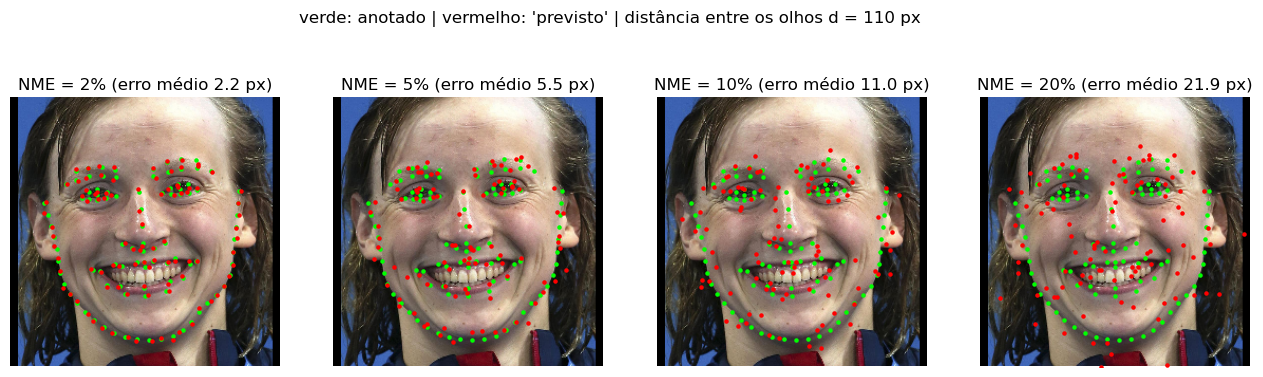

In [23]:
recorte, gt = recortar(frontal)
d = np.linalg.norm(gt[60] - gt[72])

fig, axs = plt.subplots(1, 4, figsize=(16, 4.6))
for ax, alvo in zip(axs, [0.02, 0.05, 0.10, 0.20]):
    ruido = rng.standard_normal((98, 2))
    ruido *= alvo * d / np.linalg.norm(ruido, axis=1).mean()  # ajusta o tamanho do ruído
    pred = gt + ruido
    ax.imshow(recorte)
    ax.scatter(*gt.T, s=5, c="lime")
    ax.scatter(*pred.T, s=5, c="red")
    ax.set(xlim=(0, TAMANHO), ylim=(TAMANHO, 0))
    ax.set_title(f"NME = {100 * nme(pred, gt):.0f}% (erro médio {alvo * d:.1f} px)")
    ax.axis("off")
fig.suptitle(f"verde: anotado | vermelho: 'previsto' | distância entre os olhos d = {d:.0f} px")
plt.show()

Como referência, o enunciado indica que uma ResNet-18 treinada no WFLW completo chega a
**NME de 4,5% a 5%** no teste. Uma face com NME acima de **10%** conta como **falha**.

Note também que, no recorte de $256 \times 256$, o olho aberto tem só ~10 px de altura
(seção 5). Na face acima, um erro de 5% de $d$ são ~5,5 px: metade da altura do olho.
Guardem isso para a seção 9.

## 8. Um treino mínimo

Agora juntamos tudo em um treino pequeno. O objetivo é ver o **laço de treino** funcionando
e criar um modelo para usar nas próximas seções — não obter um bom resultado. Em relação ao
que o trabalho pede, faltam muitas coisas: data augmentation, heatmaps, mais dados, mais
épocas, ajuste de hiperparâmetros e qualquer estratégia para os olhos.

**Divisão dos dados.** A validação (para acompanhar o treino e escolher hiperparâmetros) sai
do **treino oficial**. O teste oficial fica guardado para a avaliação final.

In [24]:
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if dispositivo.type == "cuda":
    N_TREINO, EPOCAS, LOTE, LR, PASSOS_SANIDADE = 2000, 10, 32, 3e-4, 100
else:  # sem GPU: treino bem menor (e resultado bem pior), para levar poucos minutos;
       # lotes menores e lr maior compensam um pouco o número pequeno de passos
    N_TREINO, EPOCAS, LOTE, LR, PASSOS_SANIDADE = 400, 4, 16, 1e-3, 40
N_VAL = 300

ordem = np.random.default_rng(0).permutation(len(treino))
faces_treino = [treino[i] for i in ordem[:N_TREINO]]
faces_val = [treino[i] for i in ordem[N_TREINO:N_TREINO + N_VAL]]  # validação: do TREINO


def carregar(faces):
    """Recorta todas as faces uma única vez e guarda na memória (sem augmentation)."""
    recortes, pontos = zip(*[recortar(f) for f in faces])
    return np.stack(recortes), np.stack(pontos)


inicio = time.time()
X_treino, Y_treino = carregar(faces_treino)
X_val, Y_val = carregar(faces_val)
print(f"{dispositivo}: {N_TREINO} faces de treino, {N_VAL} de validação, {EPOCAS} épocas")
print(f"X_treino {X_treino.shape} {X_treino.dtype} | Y_treino {Y_treino.shape} "
      f"| carregado em {time.time() - inicio:.0f} s")

cuda: 2000 faces de treino, 300 de validação, 10 épocas
X_treino (2000, 256, 256, 3) uint8 | Y_treino (2000, 98, 2) | carregado em 8 s


A rede foi pré-treinada com imagens **RGB** normalizadas pela média e pelo desvio padrão
da ImageNet. A entrada precisa seguir a mesma convenção — no treino **e** na inferência.
Por isso, a conversão fica em uma única função:

In [25]:
MEDIA = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)   # normalização da ImageNet
DESVIO = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def para_tensor(recortes):
    """(N, 256, 256, 3) uint8 RGB -> tensor (N, 3, 256, 256) normalizado, no dispositivo."""
    x = torch.from_numpy(recortes).to(dispositivo).permute(0, 3, 1, 2).float() / 255
    return (x - MEDIA.to(dispositivo)) / DESVIO.to(dispositivo)


def prever(modelo, recortes, lote=64):
    """Landmarks previstos (N, 98, 2), em pixels do recorte."""
    modelo.eval()          # BatchNorm em modo de avaliação (estatísticas do treino)
    saidas = []
    with torch.no_grad():  # sem gradientes: mais rápido e usa menos memória
        for i in range(0, len(recortes), lote):
            saidas.append(modelo(para_tensor(recortes[i:i + lote])).cpu().numpy())
    return np.concatenate(saidas) * TAMANHO

### Teste de sanidade: decorar um lote

Antes de um treino longo, um teste rápido e muito útil: a rede consegue **decorar** um único
lote de 16 faces? Se nem isso ela consegue, há um bug (alvos desalinhados, normalização
errada, taxa de aprendizado ruim...) e não adianta treinar por horas. O NME deve cair de
valores enormes para poucos por cento (sem GPU, com só 40 passos, a queda é menor, mas
ainda deve ser clara).

In [26]:
torch.manual_seed(0)
modelo = ModeloRegressao().to(dispositivo)
otimizador = torch.optim.AdamW(modelo.parameters(), lr=3e-4)
x = para_tensor(X_treino[:16])
y = torch.from_numpy(Y_treino[:16] / TAMANHO).to(dispositivo)
print(f"NME antes de treinar: {100 * nme(prever(modelo, X_treino[:16]), Y_treino[:16]).mean():.1f}%")

for passo in range(1, PASSOS_SANIDADE + 1):
    modelo.train()
    perda = (modelo(x) - y).abs().mean()  # L1 nas coordenadas
    otimizador.zero_grad()
    perda.backward()
    otimizador.step()
    if passo % 20 == 0:
        print(f"passo {passo:3d} | perda {perda.item():.4f}")
print(f"NME depois de decorar:  {100 * nme(prever(modelo, X_treino[:16]), Y_treino[:16]).mean():.1f}%")

NME antes de treinar: 275.9%


passo  20 | perda 0.0435
passo  40 | perda 0.0126


passo  60 | perda 0.0092
passo  80 | perda 0.0092


passo 100 | perda 0.0081
NME depois de decorar:  4.2%


### O laço de treino

Cada época percorre o treino em lotes embaralhados: previsão → perda → gradientes → passo
do otimizador. No fim da época, medimos o **NME na validação**.

A perda é o erro absoluto (L1) entre as coordenadas previstas e anotadas, ambas em fração
do recorte. O L1 costuma funcionar melhor que o quadrático para landmarks: pontos muito
errados (oclusos, mal anotados) pesam menos no gradiente. A taxa de aprendizado diminui ao
longo das épocas (*cosine*), o que estabiliza o fim do treino.

In [27]:
torch.manual_seed(0)
modelo = ModeloRegressao().to(dispositivo)
otimizador = torch.optim.AdamW(modelo.parameters(), lr=LR)
agendador = torch.optim.lr_scheduler.CosineAnnealingLR(otimizador, EPOCAS)  # lr cai até 0
historico = []

for epoca in range(1, EPOCAS + 1):
    inicio = time.time()
    modelo.train()
    embaralhado = np.random.default_rng(epoca).permutation(N_TREINO)
    perdas = []
    for i in range(0, N_TREINO - LOTE + 1, LOTE):
        lote = embaralhado[i:i + LOTE]
        x = para_tensor(X_treino[lote])
        y = torch.from_numpy(Y_treino[lote] / TAMANHO).to(dispositivo)  # alvo entre 0 e 1
        perda = (modelo(x) - y).abs().mean()
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()
        perdas.append(perda.item())
    agendador.step()  # uma vez por época

    nme_val = nme(prever(modelo, X_val), Y_val).mean()
    historico.append((np.mean(perdas), nme_val))
    print(f"época {epoca:2d} | perda {np.mean(perdas):.4f} | NME validação {100 * nme_val:5.2f}%"
          f" | {time.time() - inicio:.0f} s")

época  1 | perda 0.1173 | NME validação 20.63% | 1 s


época  2 | perda 0.0398 | NME validação 14.77% | 1 s


época  3 | perda 0.0292 | NME validação 12.26% | 1 s


época  4 | perda 0.0258 | NME validação 13.80% | 1 s


época  5 | perda 0.0251 | NME validação 11.77% | 1 s


época  6 | perda 0.0218 | NME validação 10.32% | 1 s


época  7 | perda 0.0187 | NME validação  9.18% | 1 s


época  8 | perda 0.0191 | NME validação  8.83% | 1 s


época  9 | perda 0.0156 | NME validação  8.08% | 1 s


época 10 | perda 0.0148 | NME validação  7.80% | 1 s


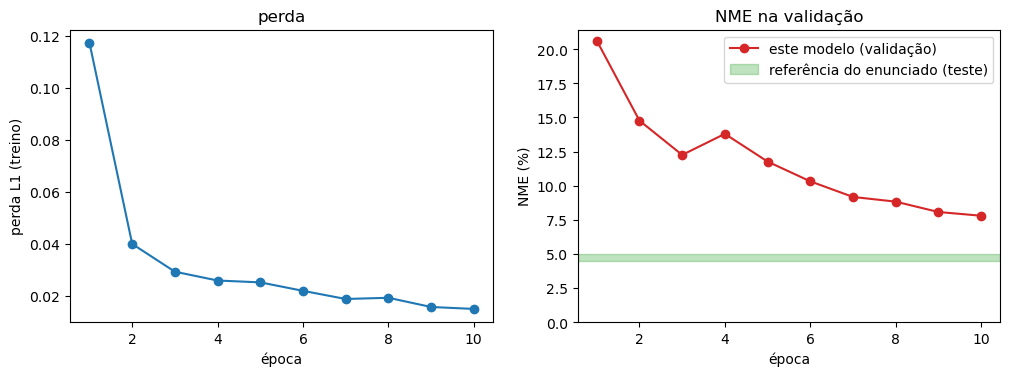

In [28]:
perdas, nmes = np.array(historico).T
epocas = np.arange(1, len(historico) + 1)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].plot(epocas, perdas, "o-")
axs[0].set(xlabel="época", ylabel="perda L1 (treino)", title="perda")
axs[1].plot(epocas, 100 * nmes, "o-", c="tab:red", label="este modelo (validação)")
axs[1].axhspan(4.5, 5, color="tab:green", alpha=0.3, label="referência do enunciado (teste)")
axs[1].set(xlabel="época", ylabel="NME (%)", title="NME na validação", ylim=(0, None))
axs[1].legend()
plt.show()

### Avaliando o modelo

O enunciado pede, no mínimo: NME global, taxa de falha (NME > 10%), NME por subconjunto,
NME por região da face e exemplos qualitativos. Na validação:

NME global:     7.80%
taxa de falha:  19.7% das faces com NME > 10%


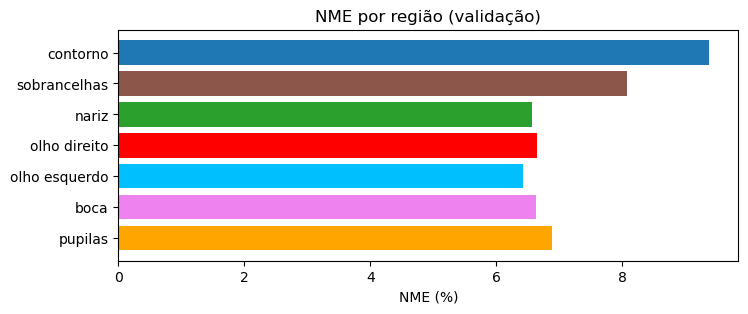

In [29]:
pred_val = prever(modelo, X_val)
nme_faces = nme(pred_val, Y_val)
print(f"NME global:     {100 * nme_faces.mean():.2f}%")
print(f"taxa de falha:  {100 * (nme_faces > 0.10).mean():.1f}% das faces com NME > 10%")

erros_pontos = erros_por_ponto(pred_val, Y_val)  # (N, 98)
nme_regiao = {nome: 100 * erros_pontos[:, list(idx)].mean() for nome, idx in REGIOES.items()}
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(list(nme_regiao), list(nme_regiao.values()), color=[CORES[n] for n in nme_regiao])
ax.invert_yaxis()
ax.set(xlabel="NME (%)", title="NME por região (validação)")
plt.show()

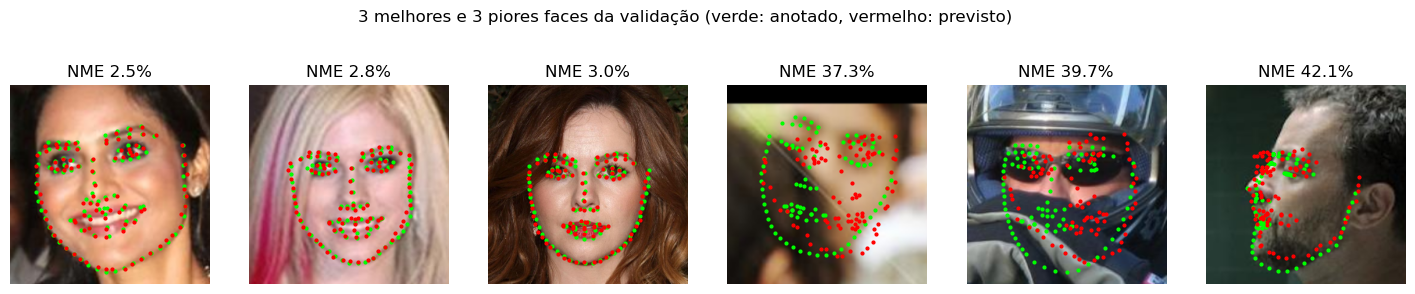

In [30]:
melhores, piores = np.argsort(nme_faces)[:3], np.argsort(nme_faces)[-3:]
fig, axs = plt.subplots(1, 6, figsize=(18, 3.6))
for ax, i in zip(axs, [*melhores, *piores]):
    ax.imshow(X_val[i])
    ax.scatter(*Y_val[i].T, s=4, c="lime")
    ax.scatter(*pred_val[i].T, s=4, c="red")
    ax.set_title(f"NME {100 * nme_faces[i]:.1f}%")
    ax.axis("off")
fig.suptitle("3 melhores e 3 piores faces da validação (verde: anotado, vermelho: previsto)")
plt.show()

As piores faces costumam ser de perfil, com oclusão ou desfocadas: a regressão direta
tende a prever uma face "média", de frente. E, mesmo nas melhores, vale olhar os **olhos**
de perto: os pontos das pálpebras raramente acompanham a abertura real do olho. A próxima
seção mede isso.

## 9. A medida dos olhos: EAR

Para decidir se o olho está aberto ou fechado, usamos uma medida geométrica: o **Eye Aspect
Ratio** (EAR), calculado com seis pontos por olho — dois cantos ($p_1$, $p_4$), dois na
pálpebra superior ($p_2$, $p_3$) e os dois logo abaixo, na inferior ($p_6$, $p_5$):

$$EAR = \frac{\|p_2-p_6\| + \|p_3-p_5\|}{2\,\|p_1-p_4\|}.$$

É a altura média do olho dividida pela largura. Olho aberto: alturas grandes. Olho
fechado: as pálpebras se encontram e as alturas tendem a zero, enquanto a largura quase não
muda. Por ser uma razão, o EAR não depende do tamanho da face na imagem.

O WFLW tem 8 pontos por olho, então é preciso **escolher** quais fazem o papel de
$p_1, \dots, p_6$. Abaixo, a escolha do exemplo do enunciado (cantos e pontos laterais das
pálpebras). Outras escolhas são possíveis e devem ser justificadas.

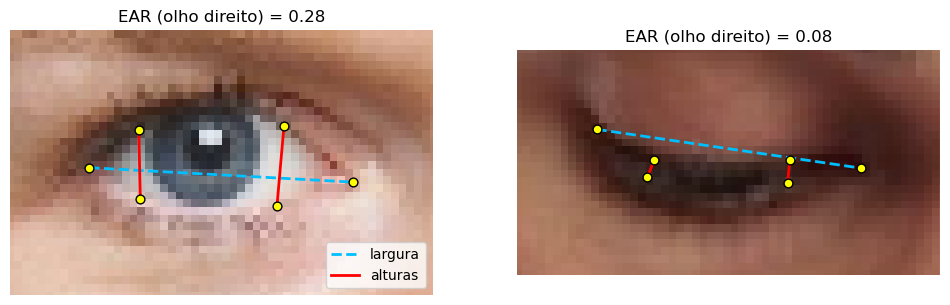

In [31]:
PONTOS_EAR = {"direito": [60, 61, 63, 64, 65, 67],    # p1..p6 no olho direito da pessoa
              "esquerdo": [72, 71, 69, 68, 75, 73]}   # equivalente, por simetria


def ear(pts, olho):
    """EAR de um olho. pts: (98, 2) ou (N, 98, 2)."""
    p1, p2, p3, p4, p5, p6 = (pts[..., i, :] for i in PONTOS_EAR[olho])
    dist = lambda a, b: np.linalg.norm(a - b, axis=-1)
    return (dist(p2, p6) + dist(p3, p5)) / (2 * dist(p1, p4))


def ear_medio(pts):
    """Média dos dois olhos (reduz o ruído)."""
    return (ear(pts, "direito") + ear(pts, "esquerdo")) / 2


aberto = buscar(teste, "28_Sports_Fan_Sports_Fan_28_663.jpg")
fechado = buscar(treino, "31_Waiter_Waitress_Waiter_Waitress_31_946.jpg")
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, face in zip(axs, [aberto, fechado]):
    recorte, pts = recortar(face)
    p1, p2, p3, p4, p5, p6 = pts[PONTOS_EAR["direito"]]
    ax.imshow(recorte)
    ax.plot(*np.array([p1, p4]).T, "--", c="deepskyblue", lw=2, label="largura")
    ax.plot(*np.array([p2, p6]).T, c="red", lw=2, label="alturas")
    ax.plot(*np.array([p3, p5]).T, c="red", lw=2)
    ax.scatter(*pts[PONTOS_EAR["direito"]].T, s=40, c="yellow", edgecolors="k", zorder=3)
    aproximar(ax, pts[60:68], margem=0.3)
    ax.set_title(f"EAR (olho direito) = {ear(pts, 'direito'):.2f}")
    ax.axis("off")
axs[0].legend(loc="lower right")
plt.show()

### Olhos fechados são raros no WFLW

O WFLW foi feito para localizar pontos, não para estudar olhos fechados. Calculando o EAR
com os pontos **anotados** de todo o treino:

EAR < 0,15 (olhos semicerrados ou fechados): 8.8% das faces
EAR < 0,05:                                  2.8% das faces


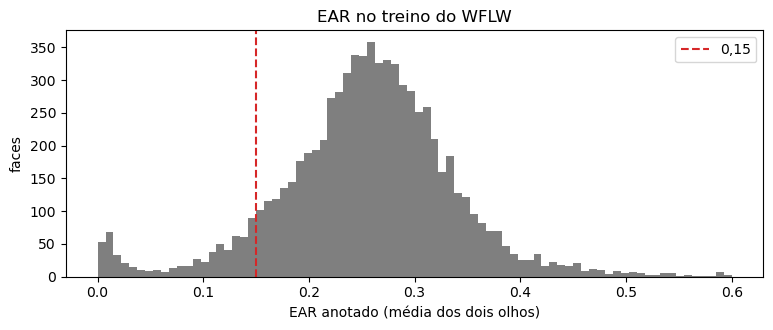

In [32]:
ear_treino = ear_medio(np.stack([f["landmarks"] for f in treino]))
print(f"EAR < 0,15 (olhos semicerrados ou fechados): {100 * (ear_treino < 0.15).mean():.1f}% das faces")
print(f"EAR < 0,05:                                  {100 * (ear_treino < 0.05).mean():.1f}% das faces")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(ear_treino, bins=80, range=(0, 0.6), color="tab:gray")
ax.axvline(0.15, c="tab:red", ls="--", label="0,15")
ax.set(xlabel="EAR anotado (média dos dois olhos)", ylabel="faces", title="EAR no treino do WFLW")
ax.legend()
plt.show()

Uma rede treinada sem levar isso em conta aprende que "olho = olho aberto" e tende a
desenhar sempre um olho médio, **inclusive quando a pessoa está de olhos fechados**. É
exatamente o que inviabiliza a Parte II.

O teste decisivo: comparar o EAR calculado com os pontos **anotados** e com os pontos
**previstos**, face a face. Se o modelo distingue olhos abertos de fechados, os pontos
ficam perto da diagonal.

EAR anotado:  mediana 0.269 | desvio padrão 0.086
EAR previsto: mediana 0.272 | desvio padrão 0.050
correlação 0.30 | erro absoluto médio 0.061
21 faces com olhos fechados (EAR anotado < 0,15): EAR previsto mediano nelas = 0.255


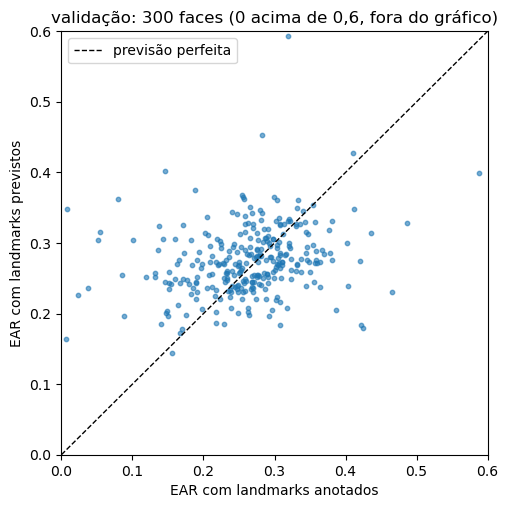

In [33]:
ear_anotado, ear_previsto = ear_medio(Y_val), ear_medio(pred_val)
correlacao = np.corrcoef(ear_anotado, ear_previsto)[0, 1]
erro_medio = np.abs(ear_anotado - ear_previsto).mean()

fechados = ear_anotado < 0.15
print(f"EAR anotado:  mediana {np.median(ear_anotado):.3f} | desvio padrão {ear_anotado.std():.3f}")
print(f"EAR previsto: mediana {np.median(ear_previsto):.3f} | desvio padrão {ear_previsto.std():.3f}")
print(f"correlação {correlacao:.2f} | erro absoluto médio {erro_medio:.3f}")
print(f"{fechados.sum()} faces com olhos fechados (EAR anotado < 0,15): "
      f"EAR previsto mediano nelas = {np.median(ear_previsto[fechados]):.3f}")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(ear_anotado, ear_previsto, s=10, alpha=0.6)
ax.plot([0, 0.6], [0, 0.6], "k--", lw=1, label="previsão perfeita")
fora = (ear_previsto > 0.6).sum()  # previsões absurdas (olho "achatado" na largura)
ax.set(xlim=(0, 0.6), ylim=(0, 0.6), xlabel="EAR com landmarks anotados",
       ylabel="EAR com landmarks previstos",
       title=f"validação: {len(ear_anotado)} faces ({fora} acima de 0,6, fora do gráfico)")
ax.legend()
plt.show()

Com esse modelo simples, os pontos não seguem a diagonal: o EAR previsto tem pouca relação
com o anotado (correlação baixa). Olhem em especial a faixa à esquerda do gráfico, das
faces de olhos fechados: o modelo as desenha com um EAR típico de **olho aberto**. Para a
Parte II, isso é fatal — o alerta nunca dispararia.

E reparem no gráfico por região da seção 8: o NME dos olhos não é pior que o das outras
regiões. **Localizar o olho não é o mesmo que medir sua abertura.** Para comparação, o enunciado relata correlação de ~0,83 para um bom modelo
ResNet-18 com estratégias para os olhos, e de ~0,51 para o **mesmo** modelo sem elas — com
NME global praticamente igual. **Por isso o NME global não basta: avaliem também o EAR.**

Duas estratégias simples sugeridas no enunciado (avaliar o efeito é parte do trabalho):

- **Sobreamostrar os olhos fechados:** sortear com mais frequência as faces com EAR anotado
  baixo. No PyTorch, com `WeightedRandomSampler`:

  ```python
  from torch.utils.data import DataLoader, WeightedRandomSampler
  pesos = np.where(ear_treino < 0.15, 5.0, 1.0)   # faces de olhos fechados: peso 5
  amostrador = WeightedRandomSampler(pesos, num_samples=len(pesos))
  loader = DataLoader(meu_dataset, batch_size=32, sampler=amostrador)
  ```

- **Peso maior nos pontos dos olhos na perda:** `pesos = torch.ones(98); pesos[60:76] = 5`
  e multiplicar o erro de cada ponto pelo seu peso antes da média.

Quanto a sobreamostragem muda a proporção vista pela rede?

In [34]:
pesos = np.where(ear_treino < 0.15, 5.0, 1.0)
fracao_original = (ear_treino < 0.15).mean()
fracao_amostrada = pesos[ear_treino < 0.15].sum() / pesos.sum()
print(f"faces com EAR < 0,15: {100 * fracao_original:.1f}% do treino, mas "
      f"{100 * fracao_amostrada:.1f}% dos exemplos sorteados com peso 5")

faces com EAR < 0,15: 8.8% do treino, mas 32.6% dos exemplos sorteados com peso 5


## 10. Da imagem à face: o detector YuNet

No vídeo não há caixa anotada: em cada frame, um **detector de faces** encontra a caixa, e
o recorte é feito com a mesma regra do treino. O enunciado recomenda o **YuNet**
(`cv2.FaceDetectorYN`), uma rede pequena que devolve, para cada face, a caixa
`(x, y, largura, altura)`, 5 pontos e uma confiança. Usar um detector pronto **só para a
caixa** é permitido; os landmarks precisam vir do modelo do grupo.

> O YuNet, como todo o OpenCV, espera imagens **BGR**. Como neste notebook trabalhamos em
> RGB, a função abaixo converte antes de detectar.

In [35]:
if YUNET.exists():  # baixado na célula de preparação
    detector = cv2.FaceDetectorYN.create(str(YUNET), "", (320, 320),
                                         score_threshold=0.7, nms_threshold=0.3)
else:
    detector = None
    print("YuNet não encontrado; as células desta seção serão puladas.")


def detectar_faces(imagem_rgb):
    """Caixas (x0, y0, x1, y1) das faces encontradas, da maior para a menor."""
    bgr = cv2.cvtColor(imagem_rgb, cv2.COLOR_RGB2BGR)  # o YuNet espera BGR
    altura, largura = bgr.shape[:2]
    detector.setInputSize((largura, altura))           # precisa ser o tamanho da imagem
    _, faces = detector.detect(bgr)
    if faces is None:                                  # None quando não há nenhuma face
        return []
    caixas = [np.array([x, y, x + w, y + h]) for x, y, w, h in faces[:, :4]]
    return sorted(caixas, key=lambda c: -(c[2] - c[0]) * (c[3] - c[1]))

Por que podemos usar a caixa do YuNet com a mesma regra de recorte do treino? Porque ela
segue **a mesma convenção** do retângulo anotado do WFLW (incluindo a testa). Vamos
comparar as duas numa imagem com várias faces (algumas anotadas no treino, outras no
teste):

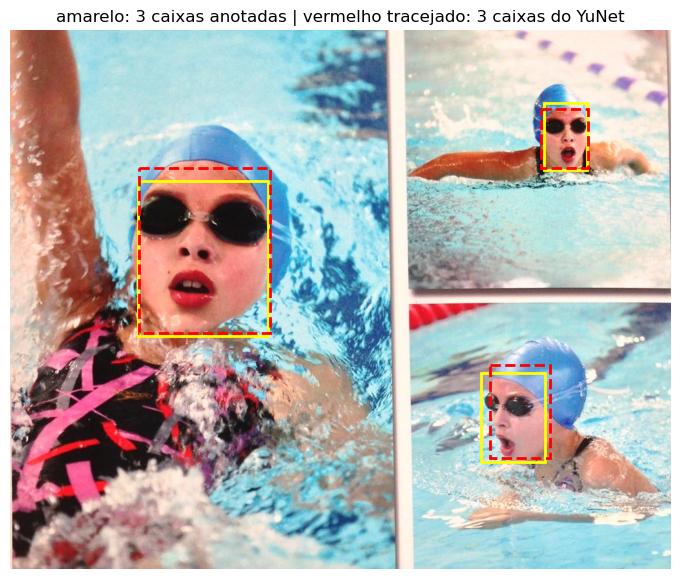

In [36]:
if detector is not None:
    nome = "41_Swimming_Swimmer_41_613.jpg"
    imagem = ler_imagem_rgb(DATA / "WFLW_images" / "41--Swimming" / nome)
    anotadas = [f for f in treino + teste if f["imagem"].name == nome]
    caixas_yunet = detectar_faces(imagem)

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(imagem)
    for f in anotadas:
        desenhar_caixa(ax, f["caixa"], "yellow", lw=2)
    for caixa in caixas_yunet:
        desenhar_caixa(ax, caixa, "red", lw=2, ls="--")
    ax.set_title(f"amarelo: {len(anotadas)} caixas anotadas | "
                 f"vermelho tracejado: {len(caixas_yunet)} caixas do YuNet")
    ax.axis("off")
    plt.show()

As caixas praticamente coincidem. Agora o **pipeline completo** numa imagem — que é, no
fundo, o que o `predict.py` da entrega precisa fazer: detectar → recortar com a regra do
treino → prever no recorte → voltar para a imagem com $M^{-1}$.

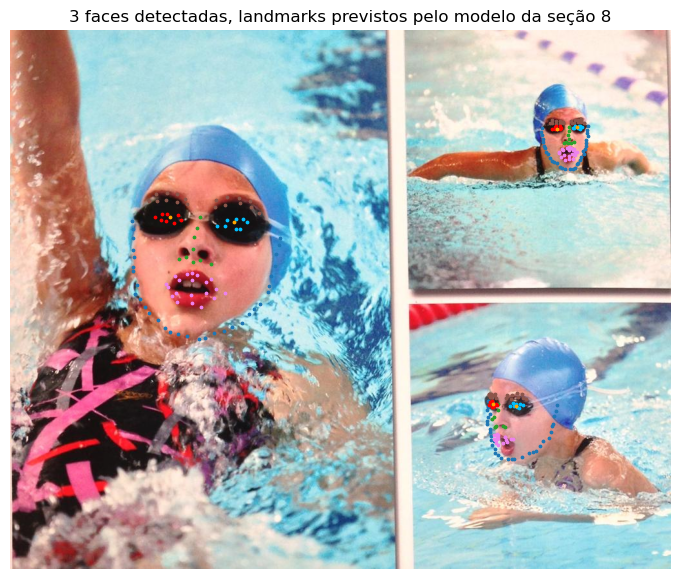

face anotada com caixa [828 112 894 216]: NME 7.0%
face anotada com caixa [198 234 400 474]: NME 3.7%
face anotada com caixa [730 532 830 670]: NME 19.4%


In [37]:
def landmarks_na_imagem(modelo, imagem_rgb):
    """Pipeline completo: array (N, 98, 2) em pixels da imagem inteira, uma linha por face."""
    faces = []
    for caixa in detectar_faces(imagem_rgb):
        M = matriz_recorte(caixa)                                  # MESMA regra do treino
        recorte = cv2.warpAffine(imagem_rgb, M, (TAMANHO, TAMANHO))
        pts = prever(modelo, recorte[None])[0]                     # no recorte
        faces.append(transformar_pontos(pts, cv2.invertAffineTransform(M)))  # na imagem
    return np.array(faces, dtype=np.float32).reshape(-1, 98, 2)


if detector is not None:
    previstas = landmarks_na_imagem(modelo, imagem)
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(imagem)
    for pts in previstas:
        desenhar_landmarks(ax, pts, s=3)
    ax.set_title(f"{len(previstas)} faces detectadas, landmarks previstos pelo modelo da seção 8")
    ax.axis("off")
    plt.show()

    # como na avaliação automática: cada face anotada é associada à prevista de menor NME
    for f in anotadas:
        melhor = min(nme(p, f["landmarks"]) for p in previstas) if len(previstas) else np.inf
        status = "não detectada" if melhor > 0.5 else f"NME {100 * melhor:.1f}%"
        print(f"face anotada com caixa {f['caixa'].astype(int)}: {status}")

> **Atenção.** Em situações difíceis (rosto muito pequeno, escuro ou parcialmente fora da
> imagem) o detector falha. A aplicação deve tratar frames **sem face** — por exemplo,
> mantendo o último estado e avisando na tela.

## 11. Análise temporal: piscadas e alertas

Um único frame com o olho fechado **não** é sonolência: uma piscada normal dura 0,1 a
0,4 s. O que importa é **por quanto tempo** o olho fica fechado. A lógica tem três partes:

1. **Limiar por frame:** o olho está "fechado" se $EAR < T_{\text{olho}}$.
2. **Duração:** medir há quanto tempo o olho está fechado, em **segundos**.
3. **Classificação:** piscada, fechamento curto ou fechamento prolongado (alerta).

Para estudar isso sem webcam, vamos **simular** o EAR de um vídeo de 30 s a 30 quadros por
segundo, com piscadas, um fechamento curto e um prolongado:

In [38]:
FPS = 30
t = np.arange(0, 30, 1 / FPS)  # instante de cada frame, em segundos
rng_sinal = np.random.default_rng(1)
ear_sinal = 0.28 + 0.015 * rng_sinal.standard_normal(len(t))  # olhos abertos, com ruído

FECHAMENTOS = [(1.5, 0.2), (6.0, 0.15), (10.0, 0.25), (14.0, 1.0), (19.0, 3.0), (25.0, 0.3)]
for inicio, duracao in FECHAMENTOS:  # (início, duração) em segundos
    trecho = (t >= inicio) & (t < inicio + duracao)
    ear_sinal[trecho] = 0.06 + 0.015 * rng_sinal.standard_normal(trecho.sum())

### Calibração do limiar

O EAR de olhos abertos varia de pessoa para pessoa e com a posição da câmera, então um
limiar fixo pode funcionar para uma pessoa e falhar para outra. Uma estratégia: nos
primeiros segundos, com a pessoa de olhos abertos, medir o EAR típico e usar uma fração
dele como limiar. A estimativa precisa ser **robusta**: houve uma piscada em 1,5 s, durante
a calibração.

In [39]:
calibracao = ear_sinal[t < 3]  # primeiros 3 segundos
print(f"média na calibração:   {calibracao.mean():.3f}  (puxada para baixo pela piscada)")
print(f"mediana na calibração: {np.median(calibracao):.3f}  (praticamente não muda)")
limiar = 0.7 * np.median(calibracao)  # a fração (0,7) é um exemplo: justifiquem a de vocês
print(f"limiar = 0,7 x mediana = {limiar:.3f}")

média na calibração:   0.264  (puxada para baixo pela piscada)
mediana na calibração: 0.279  (praticamente não muda)
limiar = 0,7 x mediana = 0.195


### Dos frames aos eventos

Com o limiar, cada frame vira "aberto" ou "fechado". Trechos consecutivos de frames
fechados formam um **fechamento**, cuja duração é o número de frames dividido pelo FPS.
Os limites entre as categorias abaixo são **exemplos**: o grupo deve definir e justificar
os seus.

In [40]:
T_PISCADA, T_ALERTA = 0.5, 1.5  # segundos (valores de exemplo)


def encontrar_fechamentos(fechado, fps):
    """Trechos consecutivos com o olho fechado: lista de (início, duração) em segundos."""
    eventos, inicio = [], None
    for i, f in enumerate(fechado):
        if f and inicio is None:          # o olho acabou de fechar
            inicio = i
        elif not f and inicio is not None:  # o olho acabou de abrir
            eventos.append((inicio / fps, (i - inicio) / fps))
            inicio = None
    if inicio is not None:                # vídeo terminou com o olho fechado
        eventos.append((inicio / fps, (len(fechado) - inicio) / fps))
    return eventos


def classificar(duracao):
    if duracao <= T_PISCADA:
        return "piscada"
    if duracao < T_ALERTA:
        return "fechamento curto"
    return "fechamento prolongado -> ALERTA"


fechado = ear_sinal < limiar
eventos = encontrar_fechamentos(fechado, FPS)
for inicio, duracao in eventos:
    print(f"t = {inicio:5.2f} s | duração {duracao:.2f} s | {classificar(duracao)}")

t =  1.50 s | duração 0.20 s | piscada
t =  6.00 s | duração 0.17 s | piscada
t = 10.00 s | duração 0.27 s | piscada
t = 14.00 s | duração 1.00 s | fechamento curto
t = 19.00 s | duração 3.00 s | fechamento prolongado -> ALERTA
t = 25.00 s | duração 0.30 s | piscada


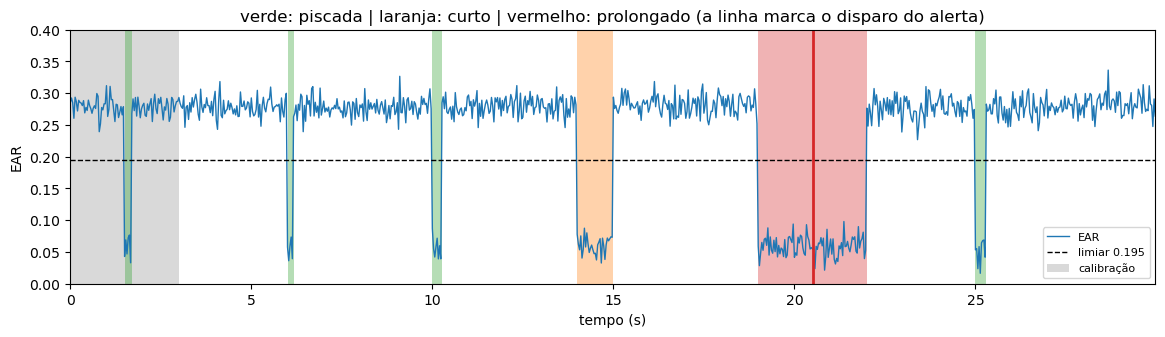

In [41]:
def plotar_sinal(ax, sinal, eventos, titulo):
    ax.plot(t, sinal, lw=1, label="EAR")
    ax.axhline(limiar, c="k", ls="--", lw=1, label=f"limiar {limiar:.3f}")
    ax.axvspan(0, 3, color="0.85", lw=0, label="calibração")
    cores = {"piscada": "tab:green", "fechamento curto": "tab:orange"}
    for inicio, duracao in eventos:
        tipo = classificar(duracao)
        ax.axvspan(inicio, inicio + duracao, color=cores.get(tipo, "tab:red"), alpha=0.35, lw=0)
        if tipo.endswith("ALERTA"):
            ax.axvline(inicio + T_ALERTA, c="tab:red", lw=2)  # instante em que o alerta dispara
    ax.set(xlim=(0, t[-1]), ylim=(0, 0.4), xlabel="tempo (s)", ylabel="EAR", title=titulo)


fig, ax = plt.subplots(figsize=(14, 3.3))
plotar_sinal(ax, ear_sinal, eventos, "verde: piscada | laranja: curto | "
             "vermelho: prolongado (a linha marca o disparo do alerta)")
ax.legend(loc="lower right", fontsize=8)
plt.show()

Repare na linha vermelha: **o alerta deve disparar quando o fechamento completa
$T_{\text{alerta}}$**, e não quando o olho reabre. A função `encontrar_fechamentos` olha o
sinal inteiro de uma vez (*offline*), o que é ótimo para entender e para analisar vídeos
gravados. A aplicação, porém, processa um frame por vez e não conhece o futuro: ela precisa
de uma pequena **máquina de estados** (*online*) que guarde o estado atual (aberto,
fechado, alerta) e o instante em que o olho fechou.

### O problema do ruído perto do limiar

Sinais reais não são tão bem comportados. Quando a pessoa olha para baixo, sorri ou vira o
rosto, o EAR pode ficar **perto do limiar** e cruzá-lo várias vezes, gerando muitos eventos
falsos. Simulando 2,5 s assim no fim do vídeo:

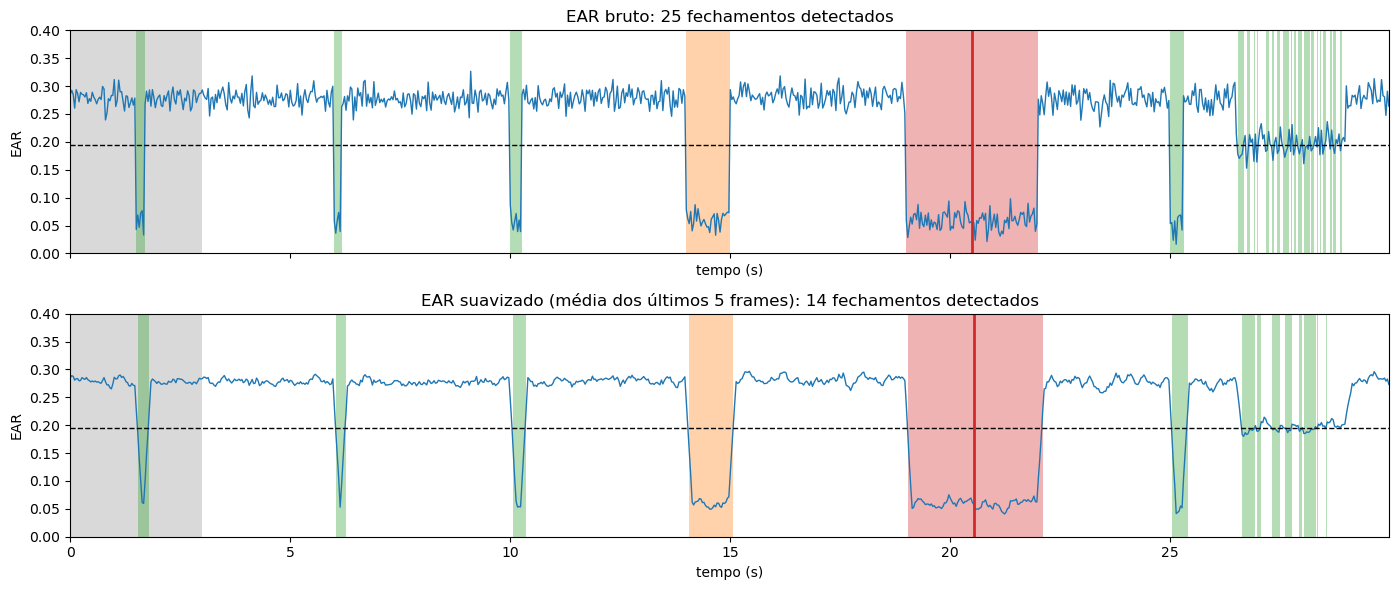

In [42]:
ear_ruidoso = ear_sinal.copy()
trecho = (t >= 26.5) & (t < 29)  # "olhando para baixo": EAR perto do limiar
ear_ruidoso[trecho] = limiar + 0.02 * rng_sinal.standard_normal(trecho.sum())


def media_movel(sinal, janela=5):
    """Média dos últimos `janela` frames: só usa o passado, como seria no app."""
    return np.array([sinal[max(0, i - janela + 1):i + 1].mean() for i in range(len(sinal))])


fig, axs = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, sinal, nome in [(axs[0], ear_ruidoso, "EAR bruto"),
                        (axs[1], media_movel(ear_ruidoso), "EAR suavizado (média dos últimos 5 frames)")]:
    ev = encontrar_fechamentos(sinal < limiar, FPS)
    plotar_sinal(ax, sinal, ev, f"{nome}: {len(ev)} fechamentos detectados")
plt.tight_layout()
plt.show()

A suavização reduz os eventos falsos, mas não resolve tudo — e tem custo: **atrasa** a
detecção e pode **apagar piscadas muito rápidas**. Outra técnica, a **histerese**, usa dois
limiares: um para fechar e outro, um pouco maior, para reabrir. Implementar e calibrar essas
técnicas (com moderação) faz parte do trabalho.

### De onde vem o tempo?

- **Arquivo de vídeo:** `t = indice_do_frame / fps_do_arquivo`. Assim o resultado não
  depende da velocidade do seu computador.
- **Webcam:** o FPS real varia com a carga da máquina e raramente é o nominal. Use o relógio
  do sistema: `t = time.monotonic() - t_inicial`.

## 12. Juntando tudo: `predict.py` e `app.py`

A entrega tem formato fixo (seção 11 do enunciado), porque parte da avaliação é automática.
O coração dela é a classe `LandmarkModel` em `predict.py`: ela recebe uma imagem **RGB
inteira** e devolve os landmarks de todas as faces em pixels dessa imagem. A função
`landmarks_na_imagem` da seção 10 já tem essa estrutura:

```python
class LandmarkModel:
    def __init__(self, weights: str, device: str = "cpu"):
        # carregar o detector (de modelos/) e o modelo (de pesos/modelo.pt)
        ...

    def predict(self, image: np.ndarray) -> np.ndarray:
        # image: RGB, uint8, (altura, largura, 3)
        # para cada face: caixa -> recorte (regra do treino) -> modelo -> M^-1
        # retorna: float (N, 98, 2) em pixels da imagem; N = 0 se não houver face
        ...
```

E o `app.py` é, essencialmente, um laço sobre os frames que usa essa classe:

```python
cap = cv2.VideoCapture(fonte)               # 0 = webcam, ou "video.mp4"
fps = cap.get(cv2.CAP_PROP_FPS)
modelo = LandmarkModel("pesos/modelo.pt")
indice, t0 = 0, time.monotonic()
while True:
    ok, frame = cap.read()                  # frame em BGR!
    if not ok:
        break
    t = indice / fps if eh_arquivo else time.monotonic() - t0   # eh_arquivo: fonte != webcam
    faces = modelo.predict(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    if len(faces) == 0:
        ...                                 # sem face: manter estado, avisar na tela
    else:
        face = max(faces, key=lambda p: np.ptp(p[:, 0]))   # por exemplo, a face mais larga
        e = ear_medio(face)
        ...                                 # calibração, máquina de estados, alerta
    ...                                     # desenhar landmarks, EAR, estado e alerta
    indice += 1
```

Antes de entregar, rodem o verificador a partir da raiz do projeto — a entrega só está no
formato certo se ele terminar com `Entrega OK`:

```bash
python src/verificar_entrega.py caminho/para/ana_bruno_julia
```

## 13. Checklist de erros silenciosos

Os erros mais comuns neste trabalho **não geram exceção**: o código roda, a perda cai, e o
resultado sai pior sem motivo aparente. Usem esta lista para revisar o código.

| Erro | O que acontece | Como perceber |
|---|---|---|
| Recortar ou aumentar a imagem sem transformar os pontos | a rede aprende pontos no lugar errado | desenhar os pontos sobre o recorte que sai do `Dataset` (seções 3 e 4) |
| Espelhar sem reordenar com o `Mirror98.txt` | exemplos contraditórios; pior nos olhos | conferir que 60–67 continua à esquerda da imagem (seção 4) |
| Trocar BGR e RGB | nenhum erro; o desempenho cai | cores estranhas ao mostrar com matplotlib; converter em um lugar só |
| Normalização diferente no treino e na inferência | idem | usar a mesma função (como `para_tensor`) nos dois |
| Recorte do vídeo diferente do recorte do treino | bom no WFLW, ruim na webcam | salvar e olhar os recortes que chegam ao modelo no `app.py` |
| Esquecer `model.eval()` e `torch.no_grad()` | BatchNorm usa estatísticas do frame; previsões instáveis | sempre os dois na inferência |
| MSE puro em heatmaps | perda baixa e estável, landmarks sem sentido | acompanhar o NME de validação desde a 1ª época (seção 5) |
| Softmax direto em heatmap com valores entre 0 e 1 | pontos puxados para o centro | seção 5 |
| Usar o teste para escolher época ou hiperparâmetros | resultado otimista e inválido | validação separada do treino oficial (seção 8) |
| Olhar só o NME global | modelo que desenha sempre o olho aberto | EAR previsto × anotado (seção 9) |
| Medir tempo em frames na webcam | durações erradas quando o FPS cai | relógio do sistema na webcam; índice/FPS em arquivo (seção 11) |

## E agora?

O que este notebook **não** fez, e que fica para o grupo: data augmentation dentro do
`Dataset`, uma cabeça melhor (heatmaps ou outra), treino com mais dados e épocas, as
estratégias para olhos fechados e a comparação de variantes, a avaliação no teste (global,
por subconjunto e por região), a máquina de estados *online*, a aplicação em vídeo e o
relatório. Uma ordem razoável de trabalho:

1. `Dataset` com recorte e augmentation **visualizados** (seções 3 e 4);
2. modelo + treino com NME de validação desde a primeira época (seções 6–8);
3. avaliação do EAR previsto × anotado e estratégias para os olhos (seção 9);
4. `predict.py` + verificador (seções 10 e 12);
5. `app.py` com calibração, máquina de estados e alerta (seção 11);
6. testes com vídeos próprios: piscadas, fechamentos longos, cabeça em movimento, óculos,
   pouca luz.